# Renewable Generation Forecasting by Source — US Northeast
### Time Series Analysis Case Study

**Data:** `usa_state_renewable_monthly_2001_2026.csv` — monthly state generation by source (GWh), Jan 2001 – Jul 2026.
**States:** CT, ME, MA, NH, RI, VT (New England) · NJ, NY, PA (Middle Atlantic).
**Targets:** hydro, wind, solar, biomass — each modelled separately (geothermal = 0 in the Northeast).

In [1]:
import warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor

import tensorflow as tf
tf.keras.utils.set_random_seed(42)                  # seeds python, numpy and TF
tf.config.experimental.enable_op_determinism()      # reproducible LSTM results
tf.get_logger().setLevel("ERROR")
from tensorflow import keras

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
sns.set_palette("tab10")

DATA_FILE = "usa_state_renewable_monthly_2001_2026.csv"
REGION = "Northeast"
START = "2013-01-01"      # common window: solar is 0 until Oct 2007 and < 30 GWh/month until 2012
SOURCES = ["hydro", "wind", "solar", "biomass"]
COLORS = {"hydro": "tab:blue", "wind": "tab:cyan", "solar": "darkorange", "biomass": "tab:green"}
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

def grid2x2(title=None, **kw):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8), **kw)
    if title: fig.suptitle(title, y=1.0)
    return fig, dict(zip(SOURCES, axes.flat))

---
# PART A 
## 1. Research Problem
The Northeast mix is **hydro-led** (NY), with **fast-growing solar**, **onshore wind** and **declining biomass**. Each source has a different driver, so grid operators need **source-level** month-ahead forecasts.

- **RQ1:** What are each source's trend/seasonal patterns, and which states drive them?
- **RQ2:** Is each series stationary; which transformations are needed?
- **RQ3:** Which family forecasts 12 months ahead best per source — (S)ARIMA(X), Holt-Winters or ML/DL?
- **RQ4:** Does a system covariate (rest of generation) beat a univariate seasonal model?
- **RQ5:** Which source is most forecastable, and what is the combined outlook?

## 2. Dataset Understanding
15,657 rows = 51 states × 307 months, **no state-name column**. Rows follow alphabetical postal-code order each month — verified against census divisions below.

In [2]:
raw = pd.read_csv(DATA_FILE, parse_dates=["month"])
SOURCES_ALL = ["hydro", "wind", "solar", "biomass", "geothermal"]

# Recover state codes: rows within each month follow alphabetical postal code order
DIVISIONS = {"New England": "CT ME MA NH RI VT", "Middle Atlantic": "NJ NY PA",
             "East North Central": "IL IN MI OH WI", "West North Central": "IA KS MN MO NE ND SD",
             "South Atlantic": "DE DC FL GA MD NC SC VA WV", "East South Central": "AL KY MS TN",
             "West South Central": "AR LA OK TX", "Mountain": "AZ CO ID MT NV NM UT WY",
             "Pacific": "AK CA HI OR WA"}
code_div = {c: d for d, cs in DIVISIONS.items() for c in cs.split()}
codes = sorted(code_div)
raw["state"] = raw.groupby("month").cumcount().map(dict(enumerate(codes)))
assert (raw["state"].map(code_div) == raw["census_division"]).all(), "state order assumption failed"
print("State-order check passed for all", raw.month.nunique(), "months")

STATE_NAMES = {"CT": "Connecticut", "MA": "Massachusetts", "ME": "Maine", "NH": "New Hampshire", "NJ": "New Jersey",
               "NY": "New York", "PA": "Pennsylvania", "RI": "Rhode Island", "VT": "Vermont"}
panel = raw[raw.census_region == REGION].rename(columns={"month": "date"}).copy()
panel["state"] = panel["state"].map(STATE_NAMES)
print("Northeast panel:", panel.shape, "| states:", panel.state.nunique(),
      "| dates:", panel.date.min().date(), "->", panel.date.max().date())
print("Missing values:", int(panel[SOURCES_ALL + ["total_generation"]].isna().sum().sum()))
panel.head()

State-order check passed for all 307 months
Northeast panel: (2763, 12) | states: 9 | dates: 2001-01-01 -> 2026-07-01
Missing values: 0


,date,census_region,census_division,hydro,wind,solar,biomass,geothermal,total_renewable,total_generation,renewable_share_pct,state
1842,2001-01-01,Northeast,New England,37.537,0.0,0.0,0.0,0.0,37.537,2930.434,1.28,Connecticut
1843,2001-02-01,Northeast,New England,33.260,0.0,0.0,0.0,0.0,33.260,1852.626,1.80,Connecticut
1844,2001-03-01,Northeast,New England,33.449,0.0,0.0,0.0,0.0,33.449,2386.253,1.40,Connecticut
1845,2001-04-01,Northeast,New England,60.494,0.0,0.0,0.0,0.0,60.494,2280.079,2.65,Connecticut
1846,2001-05-01,Northeast,New England,24.767,0.0,0.0,0.0,0.0,24.767,2356.271,1.05,Connecticut


In [3]:
win = panel[panel.date >= START]
state_tot = win.groupby("state")[SOURCES + ["total_generation"]].sum()
state_share = (100 * state_tot[SOURCES] / state_tot[SOURCES].sum()).round(1)
state_share["division"] = win.groupby("state").census_division.first()
print("Largest state per source, Jan 2013 – Jul 2026 (full shares: heatmap in Section 3):")
print({s: f"{state_share[s].idxmax()} ({state_share[s].max():.0f}%)" for s in SOURCES})

Largest state per source, Jan 2013 – Jul 2026 (full shares: heatmap in Section 3):
{'hydro': 'New York (74%)', 'wind': 'New York (40%)', 'solar': 'New York (27%)', 'biomass': 'Maine (22%)'}


In [4]:
# Regional aggregate series (targets) + one system covariate per source
agg = panel.groupby("date")[SOURCES_ALL + ["total_renewable", "total_generation"]].sum().asfreq("MS")
print("Regional annual generation before the study window (GWh):")
print(agg[SOURCES].loc[:"2012"].resample("YS").sum().round(0).rename(lambda d: d.year).T.to_string())

df = agg.loc[START:].copy()
Y = {s: df[s] for s in SOURCES}                                            # the four targets
XEXO = {s: np.log(df.total_generation - df[s]).rename("log_rest") for s in SOURCES}   # rest of generation (demand proxy)
print(f"\nStudy window: {df.index.min():%b %Y} – {df.index.max():%b %Y} ({len(df)} months)")
df[SOURCES + ["total_renewable", "total_generation"]].describe().T.round(1)

Regional annual generation before the study window (GWh):
date        2001     2002     2003     2004     2005     2006     2007     2008     2009     2010     2011     2012
hydro    30264.0  33508.0  34957.0  34582.0  36673.0  39612.0  34325.0  38598.0  39423.0  35848.0  39971.0  34265.0
wind        44.0    150.0    164.0    436.0    402.0   1047.0   1475.0   2157.0   3741.0   5078.0   5503.0   6425.0
solar        0.0      0.0      0.0      0.0      0.0      0.0      0.0      3.0     14.0     30.0    115.0    423.0
biomass  10777.0  11042.0  11026.0  11141.0  11827.0  11859.0  12301.0  12674.0  12722.0  12823.0  12357.0  12640.0

Study window: Jan 2013 – Jul 2026 (163 months)


,count,mean,std,min,25%,50%,75%,max
hydro,163.0,3145.0,383.7,2235.2,2904.4,3123.6,3403.3,4009.9
wind,163.0,957.1,306.5,367.4,707.0,979.7,1157.9,1759.0
solar,163.0,442.6,431.8,32.3,130.3,254.3,632.6,1929.4
biomass,163.0,888.0,185.3,519.6,727.3,883.4,1056.6,1201.2
total_renewable,163.0,5432.7,590.3,4065.7,4979.5,5458.0,5825.0,6976.7
total_generation,163.0,44532.6,4750.7,34287.1,40990.8,43810.8,46925.3,58075.1


In [5]:
# Data-quality checks
print("Negative values in Northeast rows:", int((panel[SOURCES_ALL + ['total_generation']] < 0).sum().sum()))
print("Geothermal in Northeast always 0:", panel.geothermal.abs().sum() == 0)
print("Rows with renewable_share_pct > 100:", int((panel.renewable_share_pct > 100).sum()))
print("Sources sum to total_renewable:", np.allclose(panel[SOURCES_ALL].sum(axis=1), panel.total_renewable, atol=1e-2))
print("Regional series with any zero month in the window:", {s: int((Y[s] <= 0).sum()) for s in SOURCES})

zero = win.groupby("state")[SOURCES].apply(lambda g: (g <= 0).sum())
rep = win.sort_values("date").groupby("state")[SOURCES].apply(lambda g: (g.diff() == 0).sum())
print("\nZero months by state and source (study window, 163 months):"); print(zero.to_string())
print("\nMonths with an exactly-repeated value vs previous month (possible carry-forward):"); print(rep.to_string())

Negative values in Northeast rows: 0
Geothermal in Northeast always 0: True
Rows with renewable_share_pct > 100: 10
Sources sum to total_renewable: True
Regional series with any zero month in the window: {'hydro': 0, 'wind': 0, 'solar': 0, 'biomass': 0}

Zero months by state and source (study window, 163 months):
               hydro  wind  solar  biomass
state                                     
Connecticut        0    33     12        0
Maine              0     0     45        0
Massachusetts      0     0      0        8
New Hampshire      0     0     97        0
New Jersey        26     0      0        0
New York           0     0      0        0
Pennsylvania       0     0      0        0
Rhode Island       5     0      1        0
Vermont            0     0      0        0

Months with an exactly-repeated value vs previous month (possible carry-forward):
               hydro  wind  solar  biomass
state                                     
Connecticut        0    37     11        0


**Observations**
- 9 states × 307 months; **no missing or negative values**; geothermal always 0.
- **Window Jan 2013 – Jul 2026 (163 months)** for all sources — solar is negligible before 2013.
- **Key states:** hydro — NY 74 %; wind — NY 40 %, PA 30 %, ME 19 %; solar — NY 27 %, MA 24 %, NJ 22 %; biomass — spread (ME, PA, NY, NH).
- **Quality flags:** zero/repeated values only in small contributors (NH solar, CT wind, NJ hydro); regional totals unaffected.

## 3. Time-Series Visualization

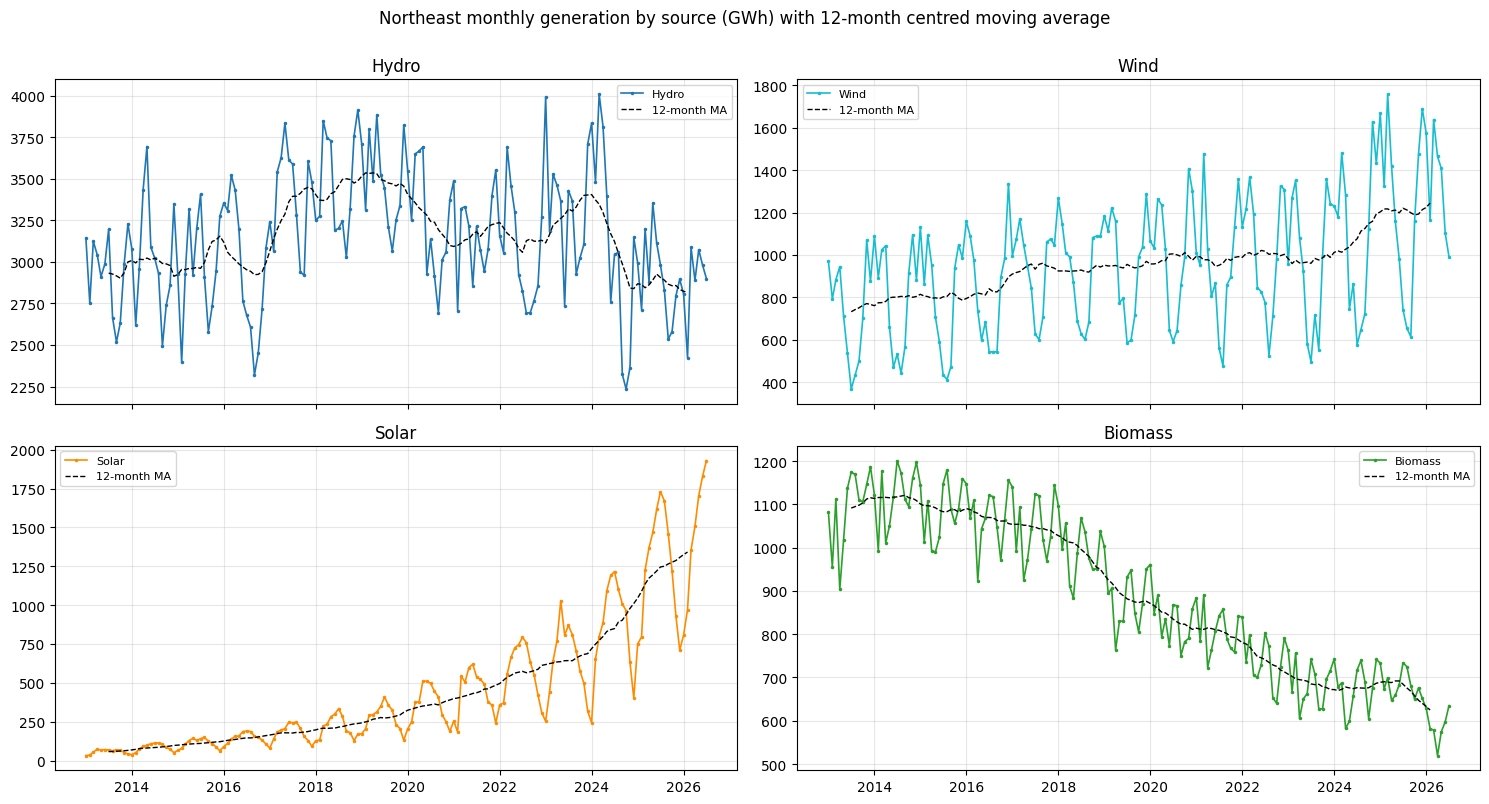

In [6]:
fig, ax = grid2x2("Northeast monthly generation by source (GWh) with 12-month centred moving average", sharex=True)
for s in SOURCES:
    ax[s].plot(Y[s], marker=".", ms=3, lw=1.2, color=COLORS[s], label=s.capitalize())
    ax[s].plot(Y[s].rolling(12, center=True).mean(), "k--", lw=1, label="12-month MA")
    ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=8)
plt.tight_layout(); plt.show()

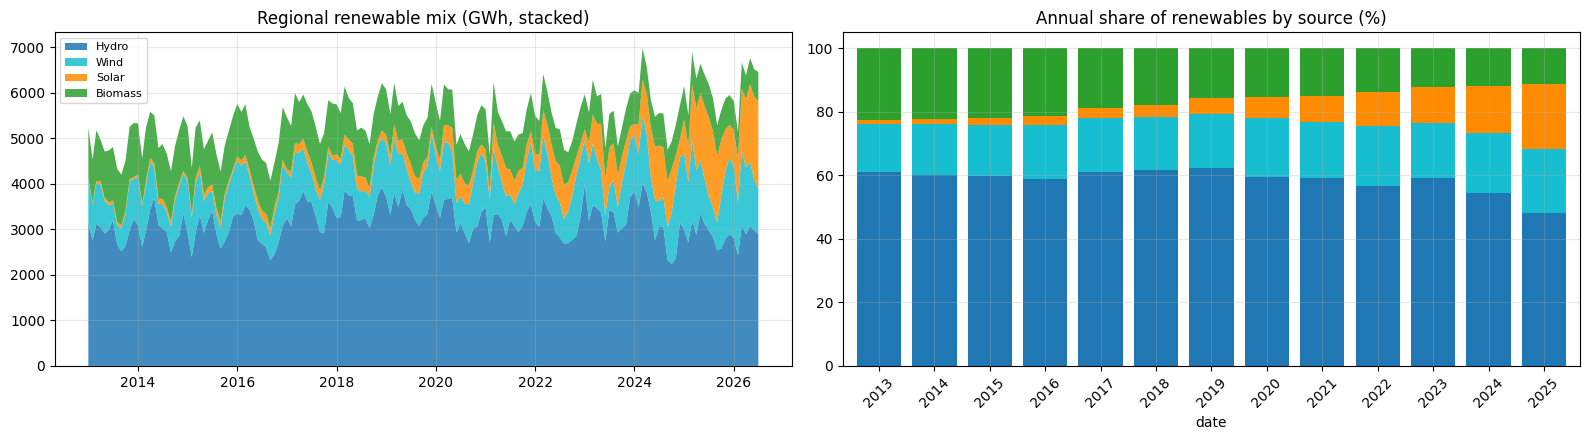

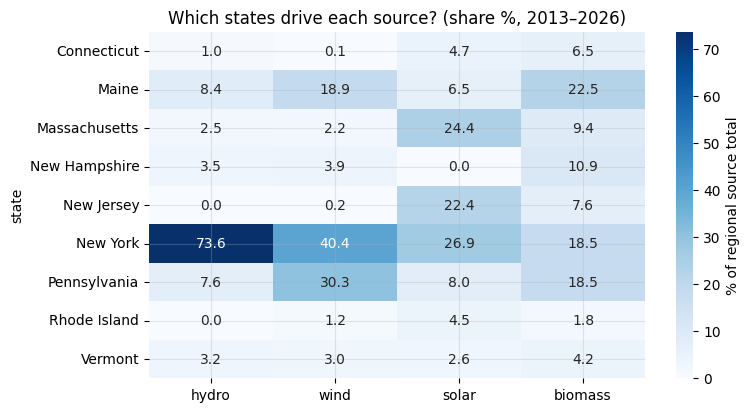

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].stackplot(df.index, *[df[s] for s in SOURCES], labels=[s.capitalize() for s in SOURCES],
                  colors=[COLORS[s] for s in SOURCES], alpha=.85)
axes[0].set_title("Regional renewable mix (GWh, stacked)"); axes[0].legend(loc="upper left", fontsize=8)
ann_mix = df[SOURCES].loc[:"2025"].resample("YS").sum()
(ann_mix.div(ann_mix.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axes[1], width=.8,
                                                          color=[COLORS[s] for s in SOURCES], legend=False)
axes[1].set_xticklabels([d.year for d in ann_mix.index], rotation=45); axes[1].set_title("Annual share of renewables by source (%)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
sns.heatmap(state_share[SOURCES], annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of regional source total"})
plt.title("Which states drive each source? (share %, 2013–2026)"); plt.show()

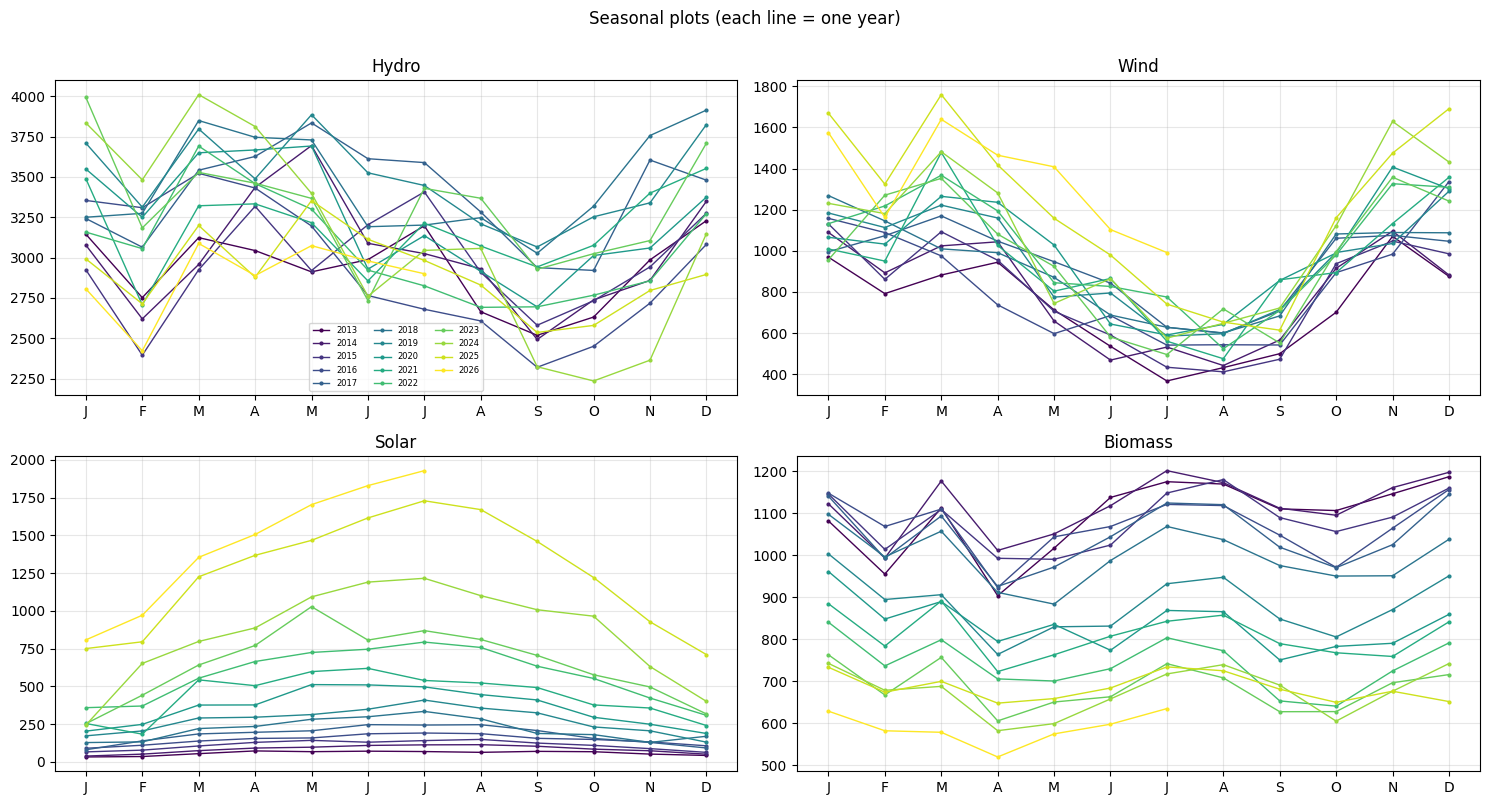

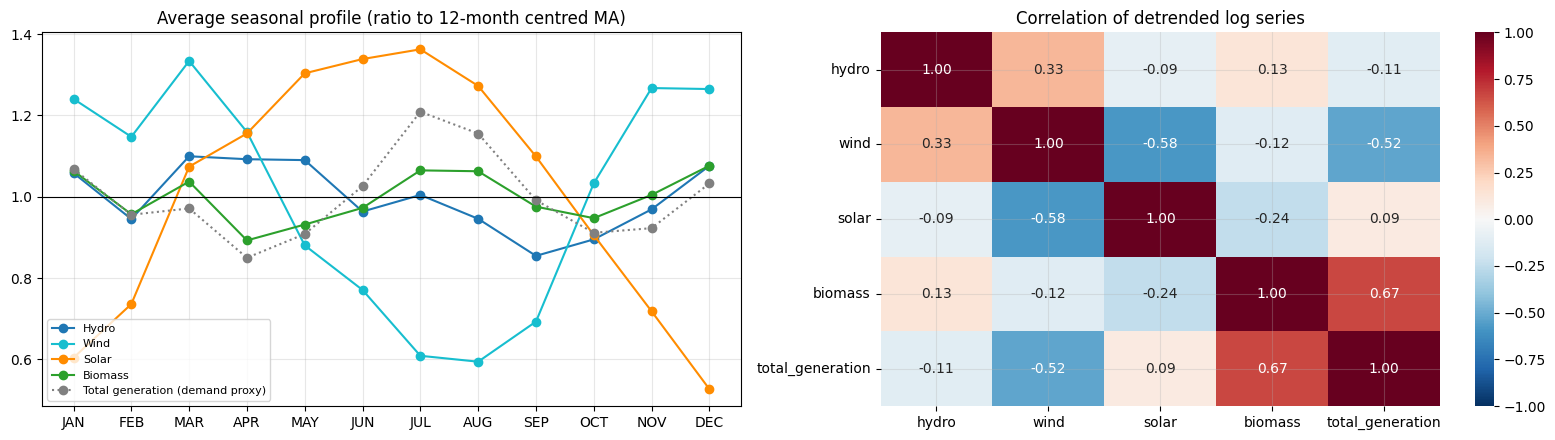

In [8]:
fig, ax = grid2x2("Seasonal plots (each line = one year)")
years = sorted(df.index.year.unique()); cmap = dict(zip(years, plt.cm.viridis(np.linspace(0, 1, len(years)))))
for s in SOURCES:
    for yr, g in Y[s].groupby(Y[s].index.year):
        ax[s].plot(g.index.month, g.values, marker="o", ms=2, lw=1, color=cmap[yr], label=yr)
    ax[s].set_xticks(range(1, 13)); ax[s].set_xticklabels([m[0] for m in MONTHS]); ax[s].set_title(s.capitalize())
ax["hydro"].legend(fontsize=6, ncol=3)
plt.tight_layout(); plt.show()

# Seasonal profiles on one unit-free axis: each series as a ratio to its own 12-month centred MA
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for s in SOURCES + ["total_generation"]:
    r = (df[s] / df[s].rolling(12, center=True).mean()).groupby(df.index.month).mean()
    axes[0].plot(r.index, r.values, marker="o", color=COLORS.get(s, "grey"), ls="-" if s in SOURCES else ":",
                 label=s.capitalize() if s in SOURCES else "Total generation (demand proxy)")
axes[0].axhline(1, color="k", lw=.8); axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(MONTHS)
axes[0].set_title("Average seasonal profile (ratio to 12-month centred MA)"); axes[0].legend(fontsize=8)

# Correlations of the detrended log series (raw levels are dominated by trends)
detr = lambda v: np.log(v) - STL(np.log(v), period=12, robust=True).fit().trend
dcorr = pd.DataFrame({s: detr(df[s]) for s in SOURCES + ["total_generation"]}).corr()
sns.heatmap(dcorr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation of detrended log series")
plt.tight_layout(); plt.show()

## 4. Trend and Seasonality Analysis

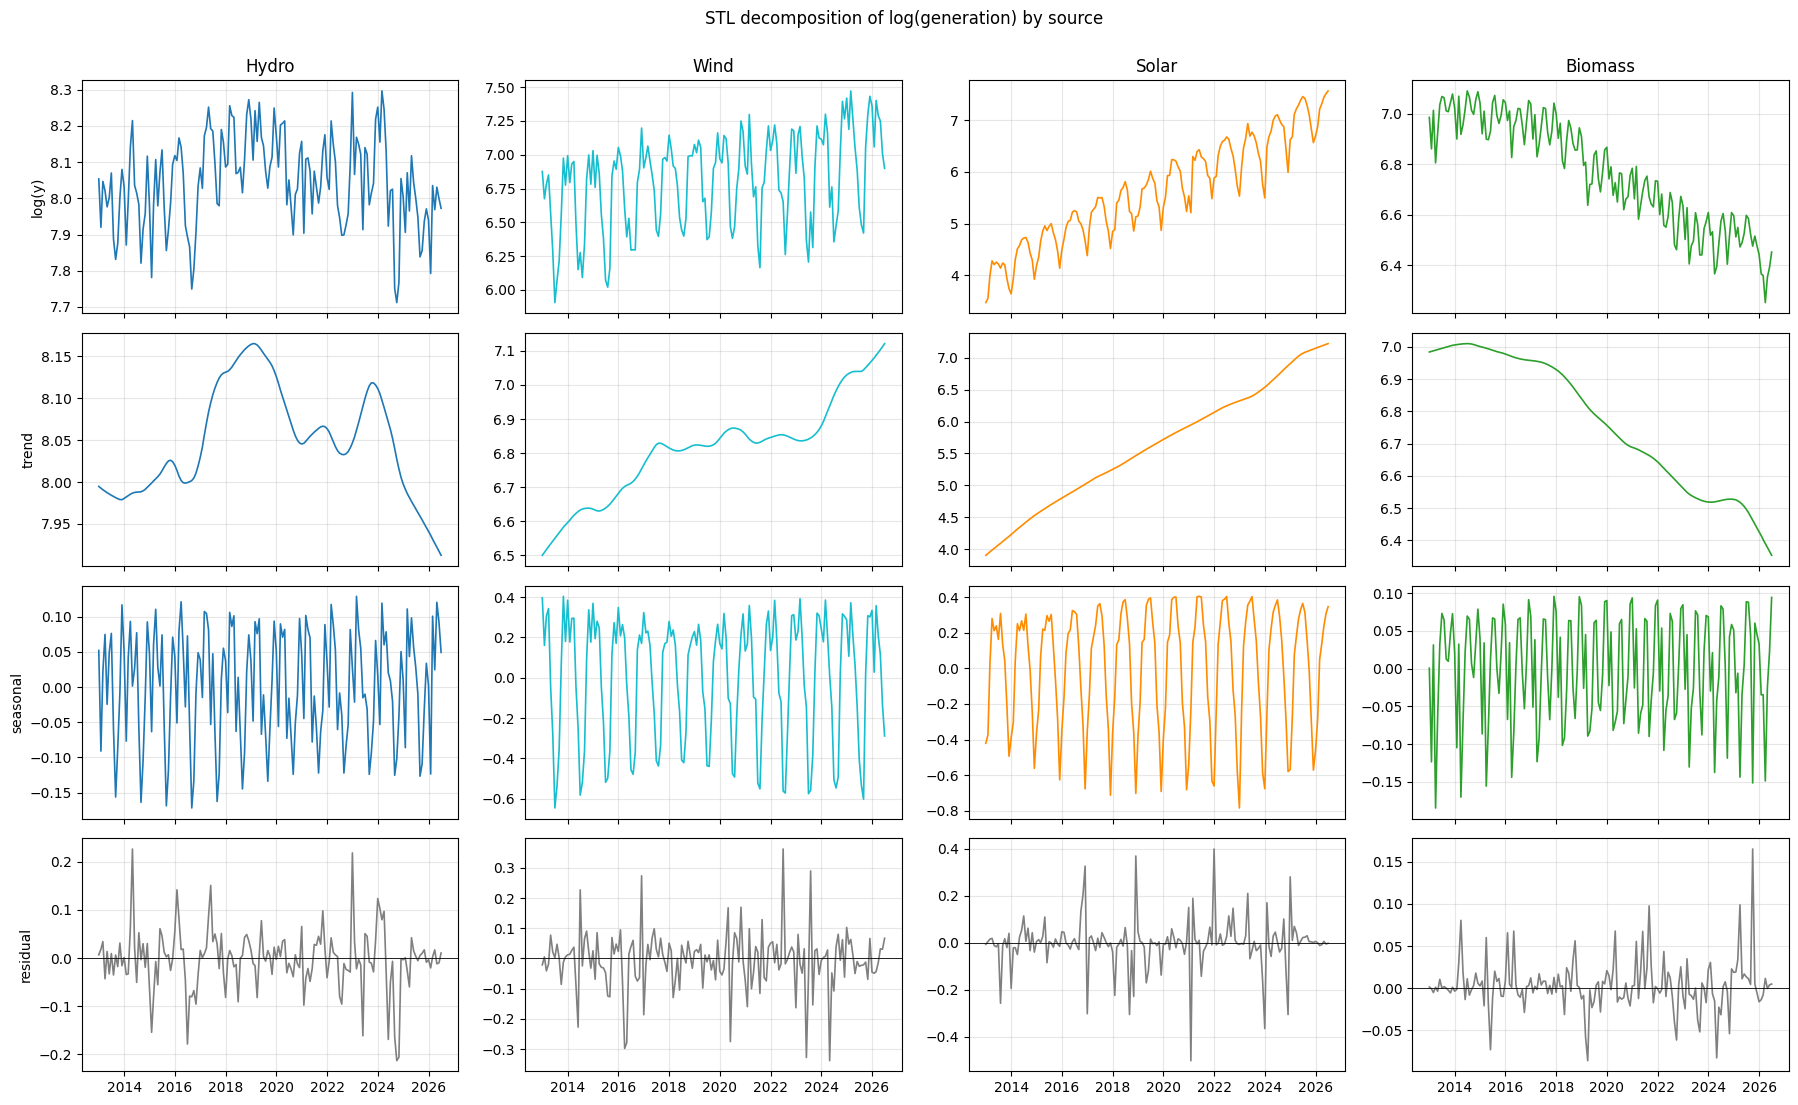

,F_trend,F_seasonal,log-linear growth %/yr,CAGR 2013→2025 %,peak month,trough month,peak/trough ratio
source,,,,,,,
hydro,0.559,0.642,-0.014,-0.076,MAR,SEP,1.287
wind,0.704,0.907,3.493,4.351,MAR,AUG,2.245
solar,0.987,0.904,26.743,29.153,JUL,DEC,2.587
biomass,0.979,0.816,-4.899,-3.815,DEC,APR,1.206


In [9]:
stl = {s: STL(np.log(Y[s]), period=12, robust=True).fit() for s in SOURCES}
fig, axes = plt.subplots(4, 4, figsize=(18, 11), sharex=True)
for j, s in enumerate(SOURCES):
    r = stl[s]
    for i, (comp, lab) in enumerate([(r.observed, "log(y)"), (r.trend, "trend"), (r.seasonal, "seasonal"), (r.resid, "residual")]):
        axes[i, j].plot(comp, color=COLORS[s] if i < 3 else "grey", lw=1.2)
        if i == 3: axes[i, j].axhline(0, color="k", lw=.6)
        if j == 0: axes[i, j].set_ylabel(lab)
    axes[0, j].set_title(s.capitalize())
fig.suptitle("STL decomposition of log(generation) by source", y=1.0); plt.tight_layout(); plt.show()

rows = []
for s in SOURCES:
    r, ys = stl[s], Y[s]
    vr = np.var(r.resid)
    idx = (ys / ys.rolling(12, center=True).mean()).groupby(ys.index.month).mean()
    ann = ys.loc[:"2025"].resample("YS").sum()
    b = np.polyfit(np.arange(len(ys)), np.log(ys), 1)[0]
    rows.append({"source": s, "F_trend": max(0, 1 - vr / np.var(r.trend + r.resid)),
                 "F_seasonal": max(0, 1 - vr / np.var(r.seasonal + r.resid)),
                 "log-linear growth %/yr": 100 * (np.exp(12 * b) - 1),
                 "CAGR 2013→2025 %": 100 * ((ann.iloc[-1] / ann.iloc[0]) ** (1 / (len(ann) - 1)) - 1),
                 "peak month": MONTHS[idx.idxmax() - 1], "trough month": MONTHS[idx.idxmin() - 1],
                 "peak/trough ratio": idx.max() / idx.min()})
trend_tab = pd.DataFrame(rows).set_index("source")
trend_tab.round(3)

**Interpretation**

| Source | F_T | F_S | Growth/yr | Peak / trough (ratio) |
|---|---|---|---|---|
| Hydro | 0.56 | 0.64 | ≈ 0 % | Mar / Sep (1.29) |
| Wind | 0.70 | **0.91** | +3.5 % | Mar / Aug (2.25) |
| Solar | **0.99** | 0.90 | **+26.7 %** | Jul / Dec (2.59) |
| Biomass | 0.98 | 0.82 | **−4.9 %** | Dec / Apr (1.21) |

- Different seasonal peaks smooth the combined renewable output.
- **Solar vs wind: r = −0.58** (detrended); **biomass tracks demand: r = 0.67**.
- Swings grow with level → model **log(y)**.

## 5. Stationarity Analysis

In [10]:
def stationarity_tests(s, name):
    s = s.dropna()
    adf = adfuller(s, autolag="AIC")
    kp = kpss(s, regression="c", nlags="auto")
    return {"series": name, "ADF stat": adf[0], "ADF p": adf[1], "KPSS stat": kp[0], "KPSS p": kp[1],
            "verdict": "Stationary" if (adf[1] < .05 and kp[1] > .05) else
                       ("Non-stationary" if (adf[1] >= .05 and kp[1] <= .05) else "Inconclusive")}

def variants(ys):
    ly = np.log(ys)
    return {"Raw y": ys, "log(y)": ly, "Δ log(y)  (d=1)": ly.diff(), "Δ12 log(y)  (D=1)": ly.diff(12),
            "Δ Δ12 log(y)  (d=1,D=1)": ly.diff(12).diff()}

st_table = pd.concat({s: pd.DataFrame([stationarity_tests(v, k) for k, v in variants(Y[s]).items()]).set_index("series")
                      for s in SOURCES}, names=["source"])
st_table.round(4)

ADF stat   ADF p  KPSS stat  KPSS p  \
source  series                                                         
hydro   Raw y                     -1.7753  0.3928     0.2650    0.10   
        log(y)                    -1.8263  0.3675     0.2636    0.10   
        Δ log(y)  (d=1)           -5.2889  0.0000     0.1151    0.10   
        Δ12 log(y)  (D=1)         -2.0910  0.2481     0.2300    0.10   
        Δ Δ12 log(y)  (d=1,D=1)   -7.0162  0.0000     0.0285    0.10   
wind    Raw y                      0.2248  0.9736     1.0583    0.01   
        log(y)                    -0.3340  0.9205     0.9614    0.01   
        Δ log(y)  (d=1)           -5.0250  0.0000     0.0108    0.10   
        Δ12 log(y)  (D=1)         -3.8645  0.0023     0.1024    0.10   
        Δ Δ12 log(y)  (d=1,D=1)   -4.8879  0.0000     0.0360    0.10   
solar   Raw y                      0.9365  0.9935     1.6568    0.01   
        log(y)                    -0.9023  0.7872     1.8927    0.01   
        Δ log(y)  (d=1)          -13.0858  0.0000     0.0171    0.10   
        Δ12 log(y)  (D=1)         -3.7573  0.0034     0.1715    0.10   
        Δ Δ12 log(y)  (d=1,D=1)   -3.1068  0.0261     0.1242    0.10   
biomass Raw y                     -0.1268  0.9467     1.8511    0.01   
        log(y)                     0.2944  0.9771     1.8494    0.01   
        Δ log(y)  (d=1)           -3.0778  0.0282     0.1357    0.10   
        Δ12 log(y)  (D=1)         -3.0846  0.0277     0.3358    0.10   
        Δ Δ12 log(y)  (d=1,D=1)   -3.5986  0.0058     0.0561    0.10   

                                        verdict  
source  series                                   
hydro   Raw y                      Inconclusive  
        log(y)                     Inconclusive  
        Δ log(y)  (d=1)              Stationary  
        Δ12 log(y)  (D=1)          Inconclusive  
        Δ Δ12 log(y)  (d=1,D=1)      Stationary  
wind    Raw y                    Non-stationary  
        log(y)                   Non-stationary  
        Δ log(y)  (d=1)              Stationary  
        Δ12 log(y)  (D=1)            Stationary  
        Δ Δ12 log(y)  (d=1,D=1)      Stationary  
solar   Raw y                    Non-stationary  
        log(y)                   Non-stationary  
        Δ log(y)  (d=1)              Stationary  
        Δ12 log(y)  (D=1)            Stationary  
        Δ Δ12 log(y)  (d=1,D=1)      Stationary  
biomass Raw y                    Non-stationary  
        log(y)                   Non-stationary  
        Δ log(y)  (d=1)              Stationary  
        Δ12 log(y)  (D=1)            Stationary  
        Δ Δ12 log(y)  (d=1,D=1)      Stationary

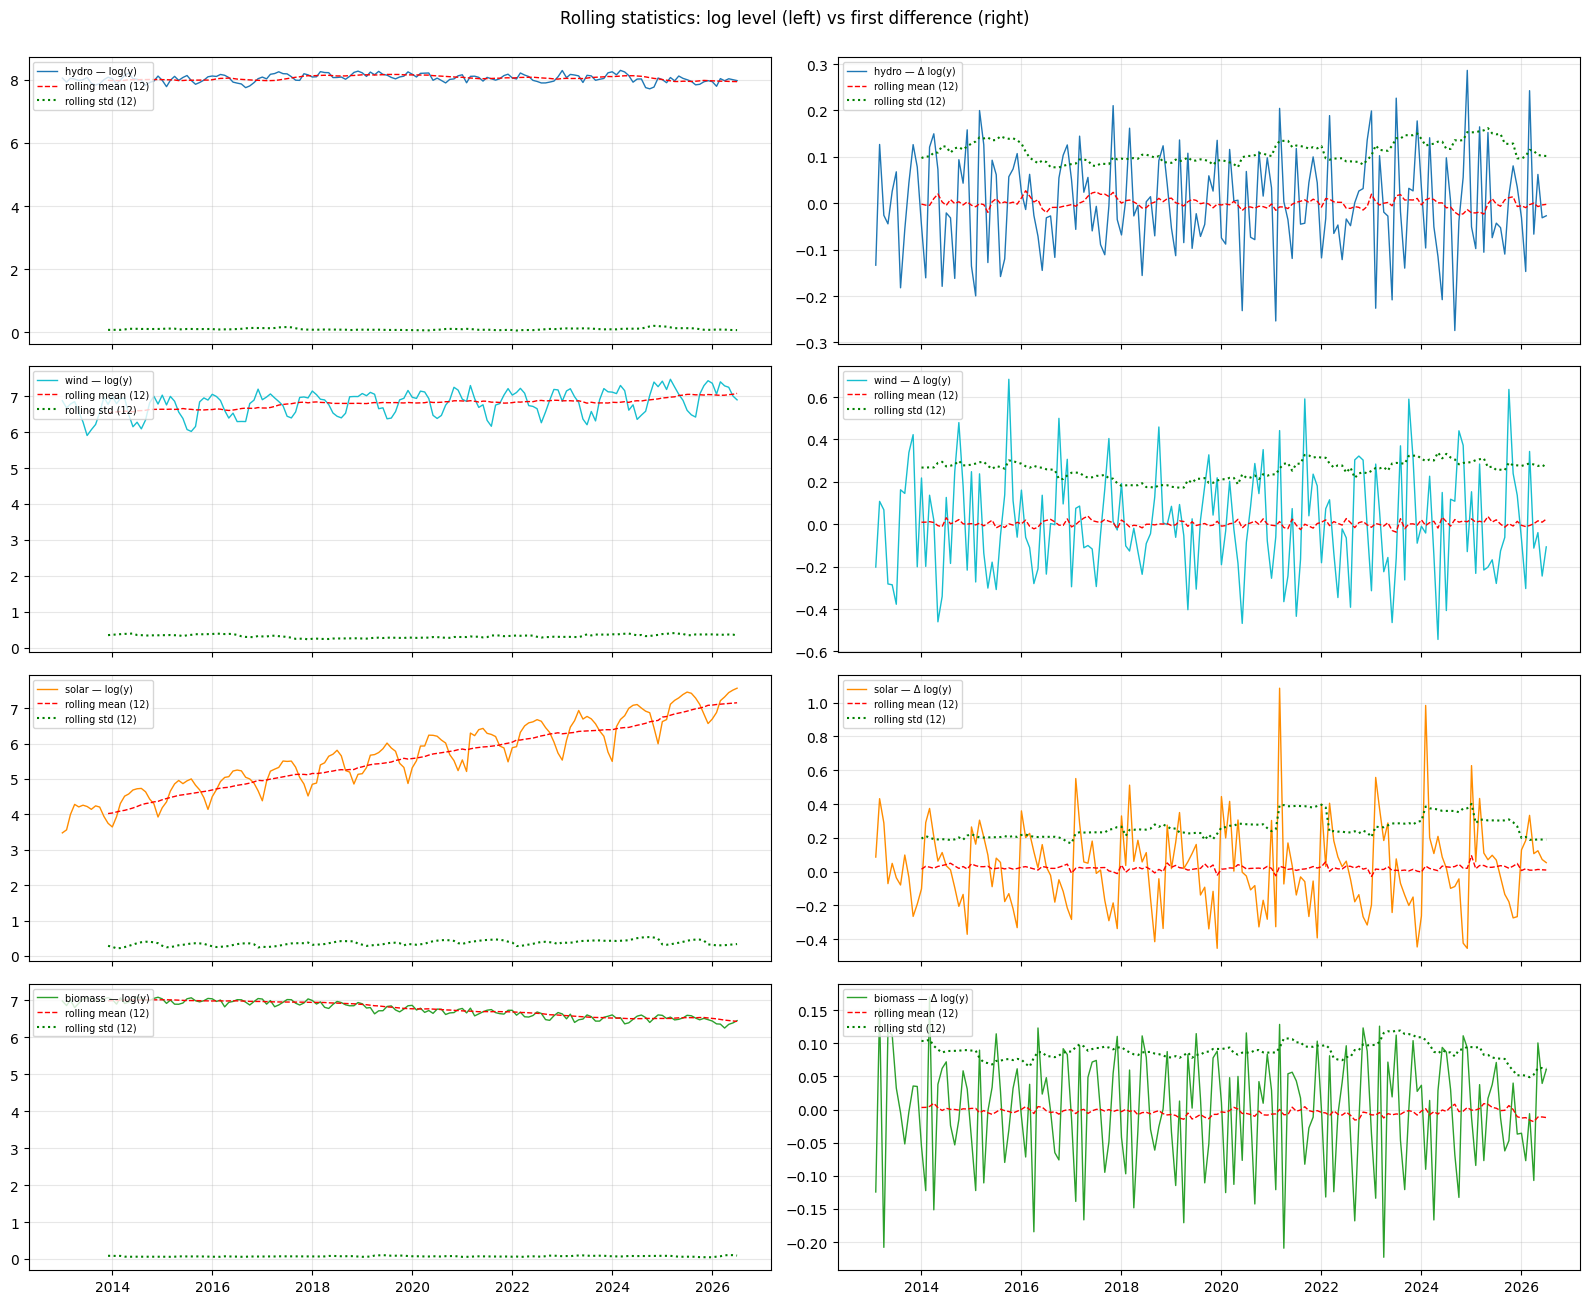

In [11]:
fig, axes = plt.subplots(4, 2, figsize=(16, 13), sharex=True)
for i, s in enumerate(SOURCES):
    for j, (k, v) in enumerate([("log(y)", np.log(Y[s])), ("Δ log(y)", np.log(Y[s]).diff())]):
        a = axes[i, j]
        a.plot(v, color=COLORS[s], lw=1, label=f"{s} — {k}")
        a.plot(v.rolling(12).mean(), "r--", lw=1, label="rolling mean (12)"); a.plot(v.rolling(12).std(), "g:", label="rolling std (12)")
        a.legend(loc="upper left", fontsize=7)
plt.suptitle("Rolling statistics: log level (left) vs first difference (right)", y=1.0); plt.tight_layout(); plt.show()

**Interpretation**
- Levels are non-stationary (hydro: inconclusive).
- **Δ log(y) is stationary for all four** → **log + d = 1**.
- D = 1 is tested as a model option in Section 9, not imposed.

## 6. ACF / PACF Analysis

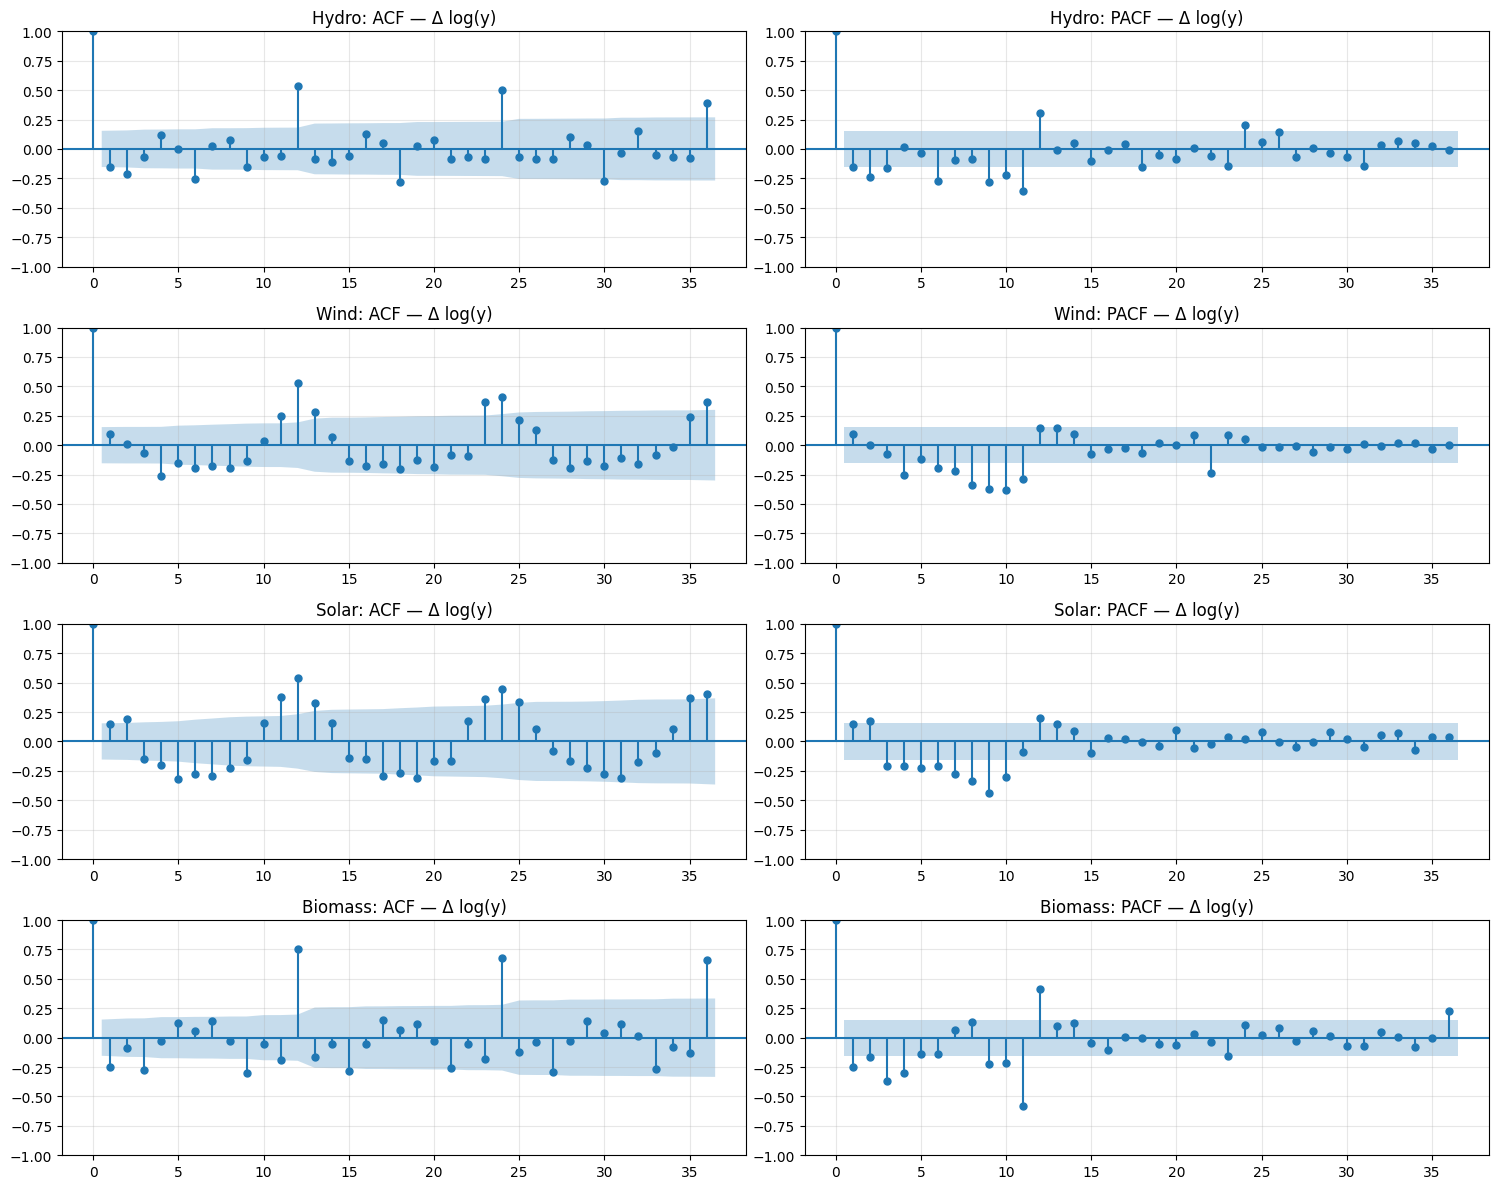

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12))
for i, s in enumerate(SOURCES):
    v = np.log(Y[s]).diff().dropna()
    plot_acf(v, lags=36, ax=axes[i, 0], title=f"{s.capitalize()}: ACF — Δ log(y)")
    plot_pacf(v, lags=36, ax=axes[i, 1], method="ywm", title=f"{s.capitalize()}: PACF — Δ log(y)")
plt.tight_layout(); plt.show()

In [13]:
def leading_sig(vals, bound, max_lag=3):
    # Number of consecutive significant lags starting at lag 1 (where the function 'cuts off')
    k = 0
    while k < max_lag and abs(vals[k + 1]) > bound:
        k += 1
    return k

acf_order, bj_rows = {}, []
for s in SOURCES:
    ly = np.log(Y[s])
    D_id = 0 if st_table.loc[(s, "Δ log(y)  (d=1)"), "verdict"] == "Stationary" else 1
    v = (ly.diff(12).diff() if D_id else ly.diff()).dropna()
    bound = 1.96 / np.sqrt(len(v))
    r_acf, r_pacf = acf(v, nlags=24), pacf(v, nlags=24, method="ywm")
    p_id, q_id = leading_sig(r_pacf, bound), leading_sig(r_acf, bound)
    spike = abs(r_acf[12]) > bound or abs(r_pacf[12]) > bound
    P_id, Q_id = int(spike and r_acf[12] > 0), int(spike and r_acf[12] < 0)
    acf_order[s] = ((p_id, 1, q_id), (P_id, D_id, Q_id, 12))
    bj_rows.append({"source": s, "series": "Δ Δ12 log(y)" if D_id else "Δ log(y)", "band ±": bound,
                    "ACF(1)": r_acf[1], "PACF(1)": r_pacf[1], "ACF(12)": r_acf[12], "PACF(12)": r_pacf[12], "ACF(24)": r_acf[24],
                    "p": p_id, "q": q_id, "P": P_id, "D": D_id, "Q": Q_id,
                    "identified model": f"SARIMA{acf_order[s][0]}{acf_order[s][1]}"})
pd.DataFrame(bj_rows).set_index("source").round(3)

,series,band ±,ACF(1),PACF(1),ACF(12),PACF(12),ACF(24),p,q,P,D,Q,identified model
source,,,,,,,,,,,,,
hydro,Δ log(y),0.154,-0.152,-0.152,0.536,0.308,0.502,0,0,1,0,0,"SARIMA(0, 1, 0)(1, 0, 0, 12)"
wind,Δ log(y),0.154,0.091,0.091,0.533,0.145,0.407,0,0,1,0,0,"SARIMA(0, 1, 0)(1, 0, 0, 12)"
solar,Δ log(y),0.154,0.146,0.146,0.539,0.201,0.448,0,0,1,0,0,"SARIMA(0, 1, 0)(1, 0, 0, 12)"
biomass,Δ log(y),0.154,-0.249,-0.249,0.756,0.413,0.680,3,1,1,0,0,"SARIMA(3, 1, 1)(1, 0, 0, 12)"


**Result**
- Strong lag-12 spike in all four (ACF 0.53–0.76) → **seasonal AR(1)**.
- Hydro, wind, solar: **SARIMA(0,1,0)(1,0,0)₁₂**; biomass: **SARIMA(3,1,1)(1,0,0)₁₂**.
- These seed the AIC search in Section 9.

## 7. Initial Findings

**Findings**
1. Hydro flat and largest (≈ 58 % of renewables); solar +27 %/yr; wind +3.5 %/yr; biomass −5 %/yr.
2. Distinct seasonal peaks: hydro/wind Mar, solar Jul, biomass Dec.
3. **log + d = 1** suffices; seasonal AR(1) in all four.


---
# PART B 
**Split (per source):** train Jan 2013 – Jul 2025 (151), test Aug 2025 – Jul 2026 (12). Section 12.1 adds a 3-year rolling-origin check.

In [14]:
H = 12
TRAIN = {s: Y[s].iloc[:-H] for s in SOURCES}
TEST = {s: Y[s].iloc[-H:] for s in SOURCES}
test_idx = Y["solar"].index[-H:]
print(f"Train: {TRAIN['solar'].index.min().date()} -> {TRAIN['solar'].index.max().date()} ({len(TRAIN['solar'])})")
print(f"Test : {test_idx.min().date()} -> {test_idx.max().date()} ({H})")

forecasts = {s: {} for s in SOURCES}     # source -> model -> test-period forecast
fitted_resid = {s: {} for s in SOURCES}  # source -> model -> in-sample residuals (original scale)

def metrics(actual, pred, train_series, m=12):
    e = actual - pred
    scale = np.mean(np.abs(train_series.values[m:] - train_series.values[:-m]))
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
            "MAPE %": 100 * np.mean(np.abs(e / actual)),
            "sMAPE %": 100 * np.mean(2 * np.abs(e) / (np.abs(actual) + np.abs(pred))),
            "MASE": np.mean(np.abs(e)) / scale}

def score(s, names):
    return pd.DataFrame({k: metrics(TEST[s], forecasts[s][k], TRAIN[s]) for k in names}).T

Train: 2013-01-01 -> 2025-07-01 (151)
Test : 2025-08-01 -> 2026-07-01 (12)


## 8. Baseline Forecasts
| Baseline | Forecast |
|---|---|
| Mean | training average |
| Naive | last value (Jul 2025) |
| Seasonal naive | same month last year |
| Drift | last value + average change × h |

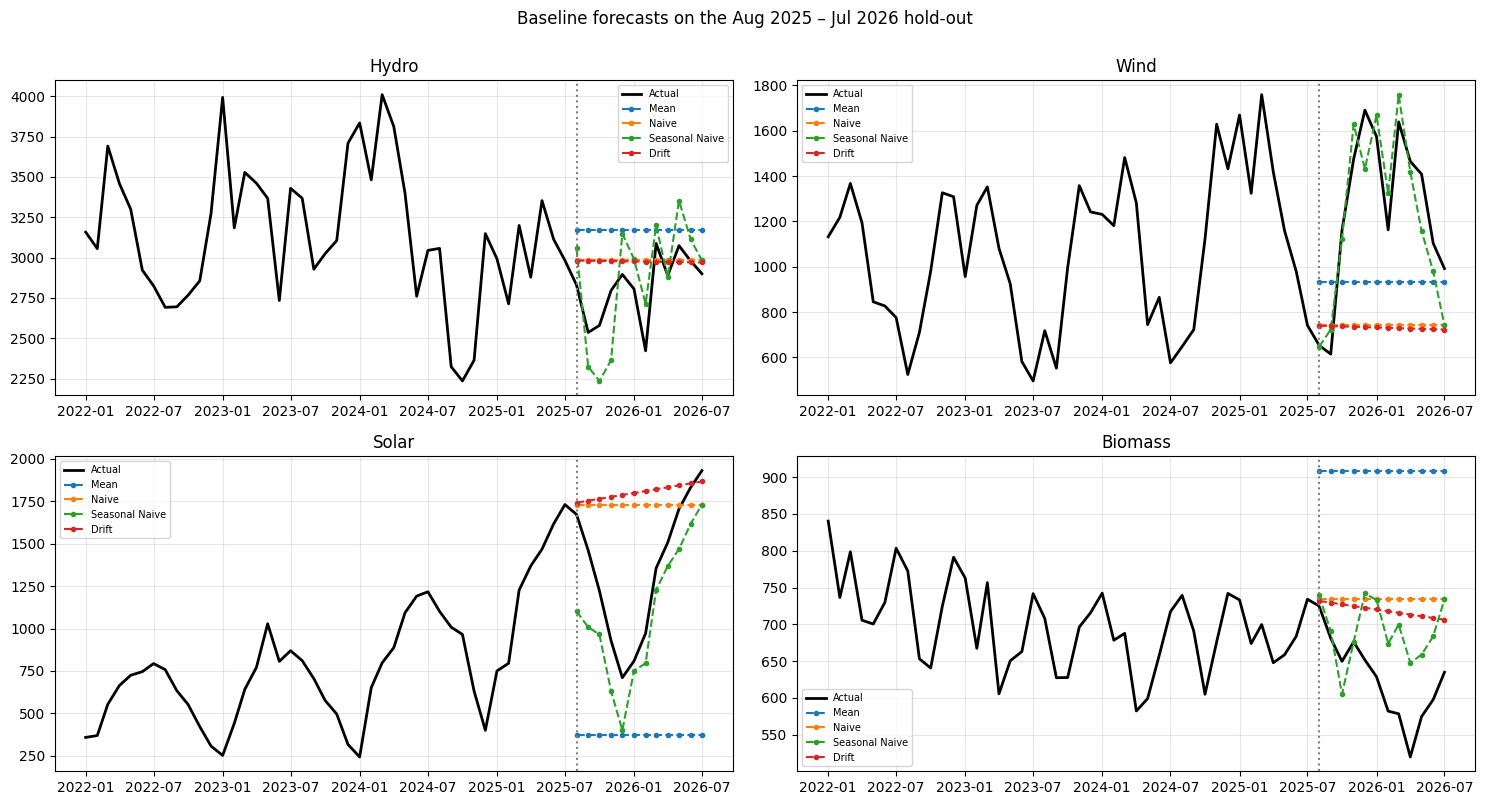

MAE     RMSE  MAPE %  sMAPE %   MASE
source  model                                                  
hydro   Mean            354.96   406.98   13.20    12.10   1.17
        Naive           199.08   259.43    7.53     7.06   0.66
        Seasonal Naive  213.59   241.58    7.75     7.78   0.70
        Drift           196.72   256.57    7.43     6.99   0.65
wind    Mean            410.66   464.88   32.52    36.30   3.34
        Naive           539.55   611.19   39.59    50.62   4.39
        Seasonal Naive  134.39   157.17   11.02    11.36   1.09
        Drift           548.67   620.33   40.27    51.76   4.46
solar   Mean            970.16  1047.43   69.35   108.03  10.44
        Naive           438.36   553.81   45.44    31.96   4.72
        Seasonal Naive  253.02   287.38   20.12    23.35   2.72
        Drift           472.52   597.54   49.04    33.74   5.09
biomass Mean            284.04   289.20   46.59    37.34   5.82
        Naive           109.19   122.00   18.39    16.42   2.24
        Seasonal Naive   72.90    84.32   12.25    11.34   1.49
        Drift            94.13   106.05   15.88    14.36   1.93

In [15]:
def baseline(name, tr, idx):
    h = np.arange(1, len(idx) + 1)
    if name == "Mean": return pd.Series(tr.mean(), index=idx)
    if name == "Naive": return pd.Series(tr.iloc[-1], index=idx)
    if name == "Seasonal Naive": return pd.Series(np.resize(tr.iloc[-12:].values, len(idx)), index=idx)
    if name == "Drift": return pd.Series(tr.iloc[-1] + h * (tr.iloc[-1] - tr.iloc[0]) / (len(tr) - 1), index=idx)

BASELINES = ["Mean", "Naive", "Seasonal Naive", "Drift"]
fig, ax = grid2x2("Baseline forecasts on the Aug 2025 – Jul 2026 hold-out")
for s in SOURCES:
    ax[s].plot(Y[s].loc["2022":], "k", lw=2, label="Actual")
    for k in BASELINES:
        forecasts[s][k] = baseline(k, TRAIN[s], test_idx)
        ax[s].plot(forecasts[s][k], "--", marker=".", label=k)
    ax[s].axvline(test_idx[0], color="grey", ls=":"); ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.concat({s: score(s, BASELINES) for s in SOURCES}, names=["source", "model"]).round(2)

## 9. ARIMA / SARIMA / SARIMAX
Fitted on **log(y)**, d = 1; orders by AIC (p, q ≤ 2; P, Q ≤ 1) per source:
- **ARIMA(p,1,q)** · **SARIMA(p,1,q)(P,0,Q)₁₂** · **SARIMA(p,1,q)(P,1,Q)₁₂** · **SARIMAX + log(rest of generation)**

*No weather data* — the covariate is a demand proxy. Observed test values are used (upper bound); Section 15 forecasts it.

In [16]:
def fit_sarimax(endog, order, sorder=(0, 0, 0, 0), exog=None):
    return SARIMAX(endog, exog=exog, order=order, seasonal_order=sorder, trend="n",
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

def grid(endog, D, seasonal_required, exog=None):
    rows = []
    for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
        if seasonal_required is None and P + Q > 0:        # plain ARIMA: no seasonal terms
            continue
        if seasonal_required and D == 0 and P + Q == 0:    # SARIMA (D=0) must have a seasonal AR/MA term
            continue
        so = (P, D, Q, 12) if (P + Q + D) else (0, 0, 0, 0)
        try:
            r = fit_sarimax(endog, (p, 1, q), so, exog=exog)
            rows.append({"order": (p, 1, q), "seasonal_order": so, "AIC": r.aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)

ARIMA_MODELS = ["ARIMA", "SARIMA (D=0)", "SARIMA (D=1)", "SARIMAX"]
grids, selected = {}, {}
for s in SOURCES:
    lt, Xtr = np.log(TRAIN[s]), XEXO[s].iloc[:-H]
    grids[s] = {"ARIMA": grid(lt, 0, None), "SARIMA (D=0)": grid(lt, 0, True),
                "SARIMA (D=1)": grid(lt, 1, True), "SARIMAX": grid(lt, 0, False, exog=Xtr)}
    selected[s] = {k: (g.loc[0, "order"], g.loc[0, "seasonal_order"]) for k, g in grids[s].items()}

pd.concat({s: pd.DataFrame([{"Model": k, "order": o, "seasonal_order": so, "AIC": grids[s][k].loc[0, "AIC"]}
                            for k, (o, so) in selected[s].items()]).set_index("Model") for s in SOURCES}, names=["source"])

order seasonal_order         AIC
source  Model                                             
hydro   ARIMA         (1, 1, 1)   (0, 0, 0, 0) -258.300959
        SARIMA (D=0)  (0, 1, 2)  (1, 0, 1, 12) -303.380616
        SARIMA (D=1)  (1, 1, 1)  (0, 1, 1, 12) -285.075317
        SARIMAX       (1, 1, 1)  (1, 0, 1, 12) -314.474927
wind    ARIMA         (2, 1, 2)   (0, 0, 0, 0)  -51.447399
        SARIMA (D=0)  (0, 1, 1)  (1, 0, 1, 12) -137.896627
        SARIMA (D=1)  (0, 1, 1)  (0, 1, 1, 12) -128.580731
        SARIMAX       (0, 1, 1)  (1, 0, 1, 12) -137.984005
solar   ARIMA         (2, 1, 2)   (0, 0, 0, 0)    9.860931
        SARIMA (D=0)  (0, 1, 1)  (1, 0, 1, 12) -124.235192
        SARIMA (D=1)  (0, 1, 1)  (0, 1, 1, 12) -109.154217
        SARIMAX       (0, 1, 1)  (1, 0, 1, 12) -122.403989
biomass ARIMA         (2, 1, 2)   (0, 0, 0, 0) -349.678689
        SARIMA (D=0)  (2, 1, 0)  (1, 0, 1, 12) -487.374835
        SARIMA (D=1)  (2, 1, 0)  (1, 1, 1, 12) -450.857387
        SARIMAX       (2, 1, 0)  (1, 0, 1, 12) -485.914009

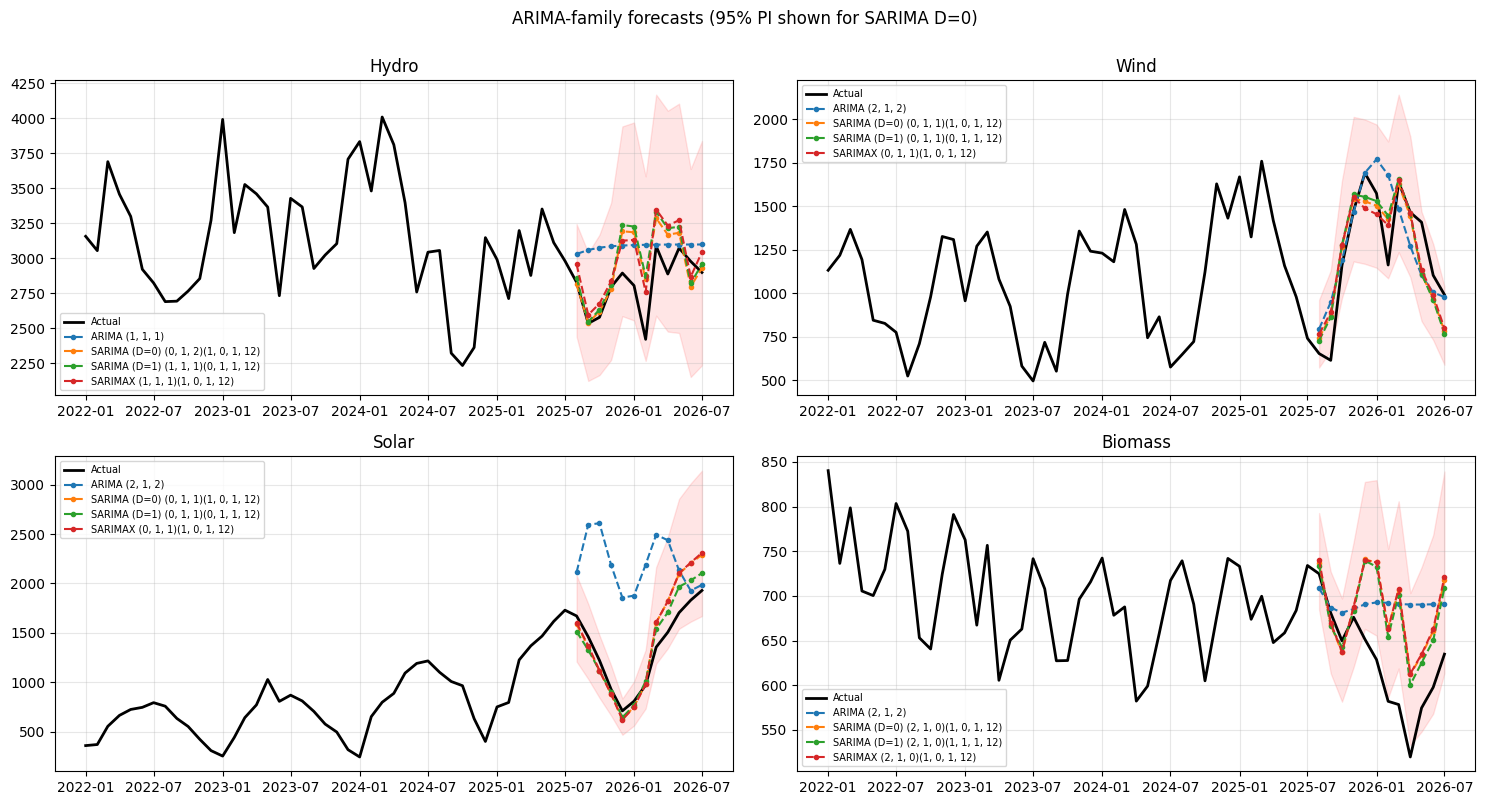

MAE    RMSE  MAPE %  sMAPE %  MASE
source  model                                              
hydro   ARIMA         270.17  332.33   10.15     9.40  0.89
        SARIMA (D=0)  165.56  220.71    5.95     5.67  0.55
        SARIMA (D=1)  188.97  245.15    6.77     6.41  0.62
        SARIMAX       190.62  217.38    6.79     6.51  0.63
wind    ARIMA         165.96  224.19   15.89    14.37  1.35
        SARIMA (D=0)  141.19  168.80   13.57    13.19  1.15
        SARIMA (D=1)  140.05  170.61   13.44    13.10  1.14
        SARIMAX       144.32  168.66   13.91    13.41  1.17
solar   ARIMA         859.08  970.17   79.30    51.28  9.25
        SARIMA (D=0)  182.28  228.75   12.31    11.69  1.96
        SARIMA (D=1)  132.85  151.59    9.26     9.10  1.43
        SARIMAX       183.19  232.71   12.38    11.73  1.97
biomass ARIMA          68.73   84.76   11.78    10.77  1.41
        SARIMA (D=0)   62.83   74.37   10.50     9.78  1.29
        SARIMA (D=1)   57.02   68.75    9.52     8.91  1.17
        SARIMAX        63.69   75.20   10.64     9.90  1.31

In [17]:
conf = {s: {} for s in SOURCES}
fig, ax = grid2x2("ARIMA-family forecasts (95% PI shown for SARIMA D=0)")
for s in SOURCES:
    lt, Xtr, Xte = np.log(TRAIN[s]), XEXO[s].iloc[:-H].to_frame(), XEXO[s].iloc[-H:].to_frame()
    ax[s].plot(Y[s].loc["2022":], "k", lw=2, label="Actual")
    for name, (o, so) in selected[s].items():
        ex_tr, ex_te = (Xtr, Xte) if name == "SARIMAX" else (None, None)
        fit = fit_sarimax(lt, o, so, exog=ex_tr)
        fc = fit.get_forecast(H, exog=ex_te)
        forecasts[s][name] = pd.Series(np.exp(fc.predicted_mean.values), index=test_idx)
        conf[s][name] = np.exp(fc.conf_int().values)
        fitted_resid[s][name] = (TRAIN[s] - np.exp(fit.fittedvalues)).iloc[13 + 12 * so[1]:]   # drop differencing burn-in
        ax[s].plot(forecasts[s][name], "--", marker=".", label=f"{name} {o}{so if sum(so) else ''}")
    ci = conf[s]["SARIMA (D=0)"]
    ax[s].fill_between(test_idx, ci[:, 0], ci[:, 1], color="r", alpha=.1)
    ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()

pd.concat({s: score(s, ARIMA_MODELS) for s in SOURCES}, names=["source", "model"]).round(2)

In [18]:
# ACF/PACF-identified model (Section 6.1) vs the AIC-selected SARIMA of the same differencing scheme
cmp_rows = []
for s in SOURCES:
    aic_key = "SARIMA (D=1)" if acf_order[s][1][1] else "SARIMA (D=0)"
    for label, (o, so) in {"ACF/PACF-identified": acf_order[s], "AIC-selected": selected[s][aic_key]}.items():
        fit = fit_sarimax(np.log(TRAIN[s]), o, so)
        fc = pd.Series(np.exp(fit.get_forecast(H).predicted_mean.values), index=test_idx)
        resid = (TRAIN[s] - np.exp(fit.fittedvalues)).iloc[13 + 12 * so[1]:]
        cmp_rows.append({"source": s, "Model": f"{label}  SARIMA{o}{so}", "AIC": fit.aic, "BIC": fit.bic,
                         "Ljung-Box p (lag 12)": acorr_ljungbox(resid, lags=[12])["lb_pvalue"].iloc[0],
                         **metrics(TEST[s], fc, TRAIN[s])})
pd.DataFrame(cmp_rows).set_index(["source", "Model"]).round(3)

AIC      BIC  \
source  Model                                                                 
hydro   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12) -264.069 -258.214   
        AIC-selected  SARIMA(0, 1, 2)(1, 0, 1, 12)        -303.381 -288.854   
wind    ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  -43.424  -37.570   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)        -137.897 -126.246   
solar   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  -22.853  -16.998   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)        -124.235 -112.585   
biomass ACF/PACF-identified  SARIMA(3, 1, 1)(1, 0, 0, 12) -457.105 -439.674   
        AIC-selected  SARIMA(2, 1, 0)(1, 0, 1, 12)        -487.375 -472.812   

                                                           Ljung-Box p (lag 12)  \
source  Model                                                                     
hydro   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)                 0.001   
        AIC-selected  SARIMA(0, 1, 2)(1, 0, 1, 12)                        0.400   
wind    ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)                 0.005   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)                        0.543   
solar   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)                 0.000   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)                        0.886   
biomass ACF/PACF-identified  SARIMA(3, 1, 1)(1, 0, 0, 12)                 0.000   
        AIC-selected  SARIMA(2, 1, 0)(1, 0, 1, 12)                        0.005   

                                                               MAE     RMSE  \
source  Model                                                                 
hydro   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  111.030  150.305   
        AIC-selected  SARIMA(0, 1, 2)(1, 0, 1, 12)         165.557  220.709   
wind    ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  196.286  226.038   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         141.186  168.798   
solar   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  260.273  289.087   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         182.284  228.752   
biomass ACF/PACF-identified  SARIMA(3, 1, 1)(1, 0, 0, 12)   90.335  102.385   
        AIC-selected  SARIMA(2, 1, 0)(1, 0, 1, 12)          62.828   74.369   

                                                           MAPE %  sMAPE %  \
source  Model                                                                
hydro   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)   4.103    4.008   
        AIC-selected  SARIMA(0, 1, 2)(1, 0, 1, 12)          5.947    5.668   
wind    ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  16.361   16.818   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         13.568   13.190   
solar   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  23.109   19.847   
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         12.313   11.687   
biomass ACF/PACF-identified  SARIMA(3, 1, 1)(1, 0, 0, 12)  15.130   13.751   
        AIC-selected  SARIMA(2, 1, 0)(1, 0, 1, 12)         10.502    9.780   

                                                            MASE  
source  Model                                                     
hydro   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  0.366  
        AIC-selected  SARIMA(0, 1, 2)(1, 0, 1, 12)         0.545  
wind    ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  1.596  
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         1.148  
solar   ACF/PACF-identified  SARIMA(0, 1, 0)(1, 0, 0, 12)  2.802  
        AIC-selected  SARIMA(0, 1, 1)(1, 0, 1, 12)         1.962  
biomass ACF/PACF-identified  SARIMA(3, 1, 1)(1, 0, 0, 12)  1.852  
        AIC-selected  SARIMA(2, 1, 0)(1, 0, 1, 12)         1.288

**Interpretation**
- AIC adds a **seasonal MA** term for every source.
- **Plain ARIMA fails on solar** (MAPE 79 %) — seasonal terms are essential.
- Best ARIMA-family MAPE: hydro SARIMA D=0 **6.0 %**, wind SARIMA D=1 **13.4 %**, solar SARIMA D=1 **9.3 %**, biomass SARIMA D=1 **9.5 %**.
- **Covariate significant only for hydro** (p < 0.001); SARIMAX ≈ SARIMA elsewhere.

**ACF/PACF vs AIC**
- AIC models fit better and have white-noise residuals (hydro, wind, solar).
- AIC forecasts better for wind, solar, biomass; the **simpler ACF/PACF model wins for hydro** (4.1 % vs 5.9 %).

## 10. Holt-Winters
Additive vs multiplicative, ± damped trend (m = 12). Lowest test RMSE is carried forward per source.

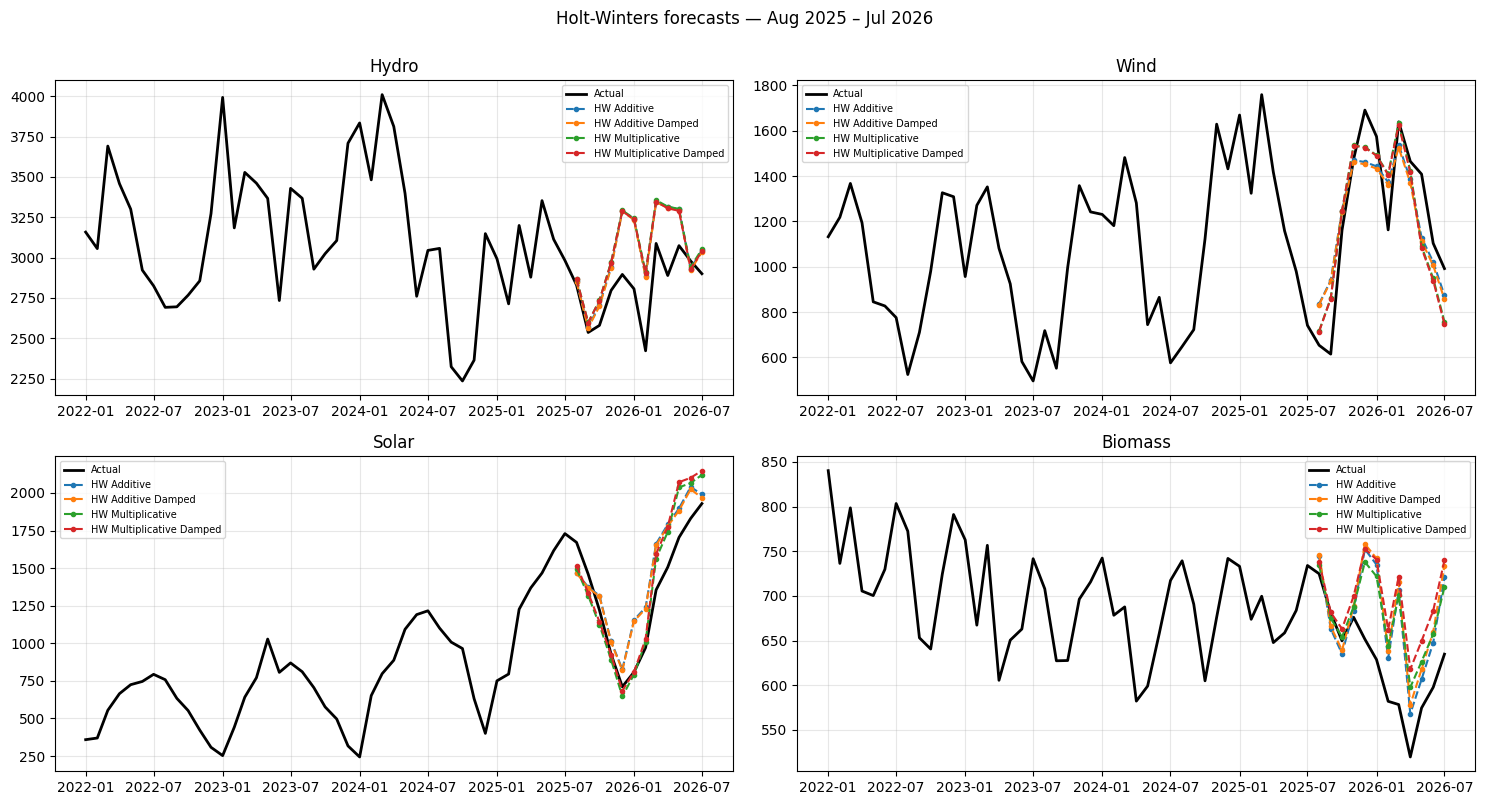

Lowest AIC per source : {'hydro': 'HW Additive', 'wind': 'HW Multiplicative', 'solar': 'HW Multiplicative', 'biomass': 'HW Multiplicative Damped'}
Lowest hold-out RMSE (carried forward): {'hydro': 'HW Additive Damped', 'wind': 'HW Multiplicative', 'solar': 'HW Multiplicative', 'biomass': 'HW Multiplicative'}


AIC  alpha   beta  gamma    phi  \
source  model                                                            
hydro   HW Additive               1653.113  0.644  0.000  0.000    NaN   
        HW Additive Damped        1655.121  0.646  0.000  0.000  0.800   
        HW Multiplicative         1653.711  0.644  0.000  0.000    NaN   
        HW Multiplicative Damped  1655.631  0.641  0.000  0.000  0.972   
wind    HW Additive               1461.318  0.121  0.000  0.000    NaN   
        HW Additive Damped        1464.168  0.131  0.000  0.000  0.995   
        HW Multiplicative         1459.086  0.115  0.000  0.000    NaN   
        HW Multiplicative Damped  1462.265  0.135  0.000  0.000  0.995   
solar   HW Additive               1315.087  0.162  0.162  0.838    NaN   
        HW Additive Damped        1318.017  0.166  0.166  0.834  0.995   
        HW Multiplicative         1240.673  0.156  0.114  0.093    NaN   
        HW Multiplicative Damped  1243.350  0.198  0.164  0.082  0.995   
biomass HW Additive               1071.576  0.521  0.000  0.000    NaN   
        HW Additive Damped        1074.413  0.529  0.000  0.000  0.995   
        HW Multiplicative         1063.081  0.509  0.000  0.000    NaN   
        HW Multiplicative Damped  1062.691  0.502  0.000  0.000  0.800   

                                      MAE     RMSE  MAPE %  sMAPE %   MASE  
source  model                                                               
hydro   HW Additive               227.173  276.947   8.134    7.665  0.748  
        HW Additive Damped        222.660  273.041   7.971    7.516  0.733  
        HW Multiplicative         238.726  285.234   8.572    8.071  0.786  
        HW Multiplicative Damped  233.707  279.413   8.396    7.914  0.770  
wind    HW Additive               152.576  177.125  14.963   14.014  1.241  
        HW Additive Damped        159.174  181.637  15.385   14.562  1.294  
        HW Multiplicative         141.953  171.294  13.408   13.262  1.154  
        HW Multiplicative Damped  144.899  174.001  13.612   13.533  1.178  
solar   HW Additive               187.763  210.000  15.765   14.341  2.021  
        HW Additive Damped        179.425  202.352  15.123   13.802  1.932  
        HW Multiplicative         147.807  175.404  10.038    9.760  1.591  
        HW Multiplicative Damped  151.070  190.626   9.804    9.330  1.626  
biomass HW Additive                54.844   67.268   9.008    8.450  1.125  
        HW Additive Damped         61.285   74.215  10.096    9.410  1.257  
        HW Multiplicative          55.042   66.638   9.201    8.616  1.129  
        HW Multiplicative Damped   71.007   83.846  11.860   10.947  1.456

In [19]:
HW_SPECS = {
    "HW Additive": dict(trend="add", seasonal="add", damped_trend=False),
    "HW Additive Damped": dict(trend="add", seasonal="add", damped_trend=True),
    "HW Multiplicative": dict(trend="add", seasonal="mul", damped_trend=False),
    "HW Multiplicative Damped": dict(trend="add", seasonal="mul", damped_trend=True),
}
def hw_fit(ys, name):
    return ExponentialSmoothing(ys, seasonal_periods=12, initialization_method="estimated", **HW_SPECS[name]).fit(optimized=True)

hw_rows, best_hw = [], {}
fig, ax = grid2x2("Holt-Winters forecasts — Aug 2025 – Jul 2026")
for s in SOURCES:
    ax[s].plot(Y[s].loc["2022":], "k", lw=2, label="Actual")
    for name in HW_SPECS:
        fit = hw_fit(TRAIN[s], name)
        forecasts[s][name] = pd.Series(fit.forecast(H).values, index=test_idx)
        fitted_resid[s][name] = TRAIN[s] - fit.fittedvalues
        hw_rows.append({"source": s, "model": name, "AIC": fit.aic, "alpha": fit.params["smoothing_level"],
                        "beta": fit.params["smoothing_trend"], "gamma": fit.params["smoothing_seasonal"],
                        "phi": fit.params.get("damping_trend", np.nan), **metrics(TEST[s], forecasts[s][name], TRAIN[s])})
        ax[s].plot(forecasts[s][name], "--", marker=".", label=name)
    ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()

hw_tab = pd.DataFrame(hw_rows).set_index(["source", "model"])
for s in SOURCES:
    best_hw[s] = hw_tab.loc[s, "RMSE"].idxmin()
print("Lowest AIC per source :", {s: hw_tab.loc[s, "AIC"].idxmin() for s in SOURCES})
print("Lowest hold-out RMSE (carried forward):", best_hw)
hw_tab.round(3)

**Interpretation**
- **Multiplicative** best for solar (MAPE 10.0 %), wind (13.4 %) and biomass (9.2 %).
- **Hydro:** additive damped (8.0 %) — still worse than SARIMA and Naive.
- β = γ ≈ 0 for most sources → fixed slope and seasonal shape; damping did not help.

## 11. ML / DL Models
Target = **log-growth** $z_t = \log y_t - \log y_{t-1}$ (trees can't extrapolate trends). Features: lags 1, 2, 3, 12, sin/cos month, Δlog(rest of generation). Recursive 12-step forecasts.
- **Random Forest** · **Gradient Boosting** · **XGBoost** · **LSTM** (12-month window, 32 units)

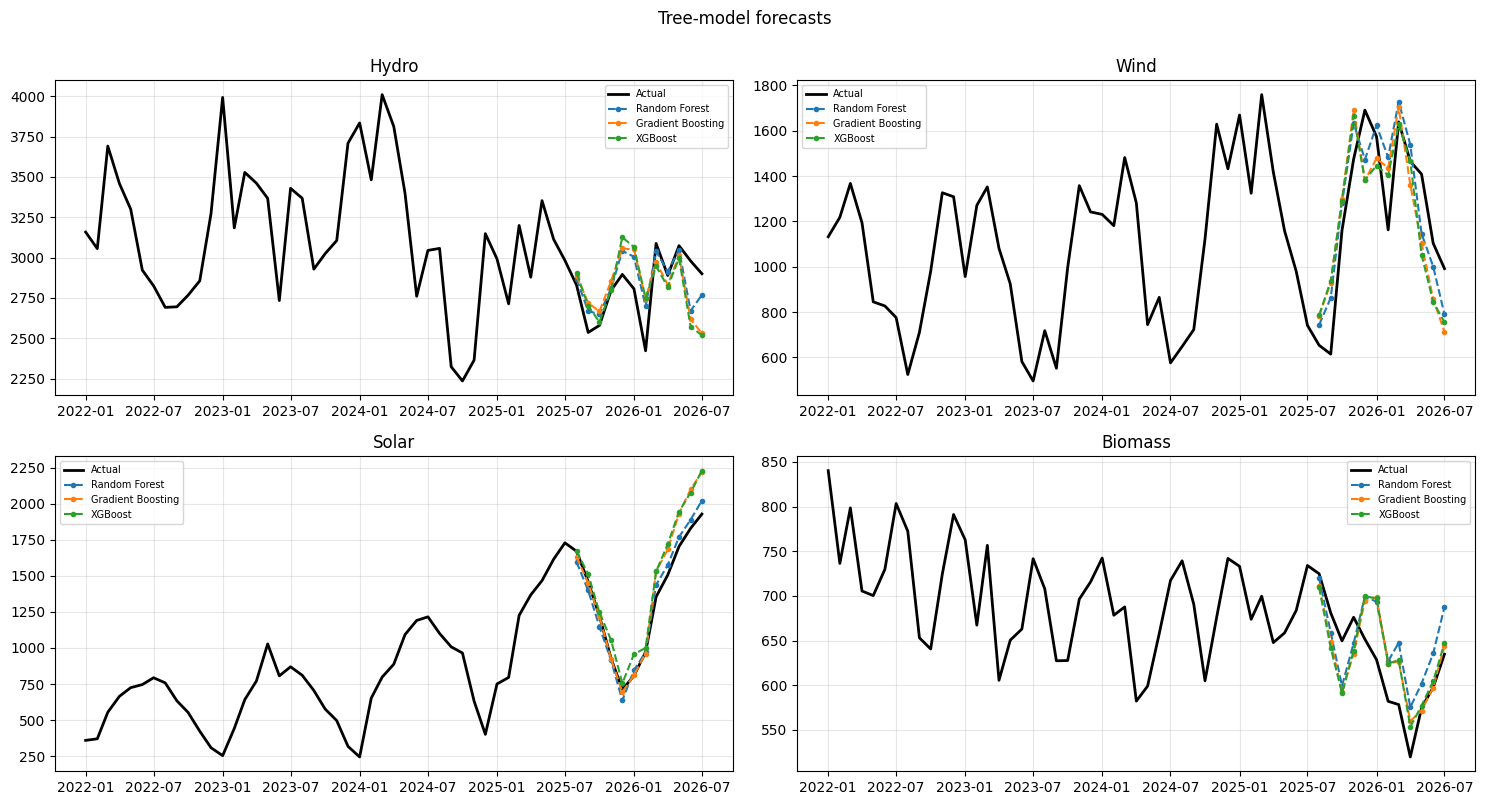

Feature importance:


hydro                                    wind  \
           Random Forest Gradient Boosting XGBoost Random Forest   
z_lag1             0.106             0.113   0.087         0.116   
z_lag2             0.106             0.125   0.104         0.088   
z_lag3             0.097             0.092   0.077         0.071   
z_lag12            0.432             0.327   0.293         0.394   
month_sin          0.051             0.036   0.142         0.046   
month_cos          0.109             0.149   0.191         0.199   
d_log_rest         0.099             0.159   0.106         0.086   

                                             solar                            \
           Gradient Boosting XGBoost Random Forest Gradient Boosting XGBoost   
z_lag1                 0.114   0.091         0.119             0.204   0.091   
z_lag2                 0.089   0.080         0.076             0.088   0.068   
z_lag3                 0.080   0.065         0.131             0.135   0.110   
z_lag12                0.369   0.237         0.100             0.094   0.078   
month_sin              0.060   0.170         0.424             0.364   0.446   
month_cos              0.199   0.283         0.084             0.083   0.171   
d_log_rest             0.089   0.074         0.065             0.032   0.036   

                 biomass                            
           Random Forest Gradient Boosting XGBoost  
z_lag1             0.058             0.071   0.062  
z_lag2             0.047             0.043   0.053  
z_lag3             0.032             0.034   0.036  
z_lag12            0.515             0.467   0.401  
month_sin          0.035             0.039   0.110  
month_cos          0.008             0.006   0.036  
d_log_rest         0.306             0.340   0.303

MAE    RMSE  MAPE %  sMAPE %  MASE
source  model                                                   
hydro   Random Forest      117.64  151.92    4.28     4.24  0.39
        Gradient Boosting  172.90  208.96    6.23     6.23  0.57
        XGBoost            179.91  224.06    6.43     6.45  0.59
wind    Random Forest      161.05  181.40   14.79    14.22  1.31
        Gradient Boosting  206.25  225.05   19.06    18.71  1.68
        XGBoost            193.24  222.58   18.13    17.80  1.57
solar   Random Forest       59.00   64.63    4.51     4.54  0.64
        Gradient Boosting  102.42  151.37    6.28     5.93  1.10
        XGBoost            134.07  166.37    9.80     9.18  1.44
biomass Random Forest       42.25   45.89    6.95     6.75  0.87
        Gradient Boosting   33.41   39.57    5.39     5.31  0.69
        XGBoost             34.52   39.99    5.55     5.47  0.71

In [20]:
LAGS = [1, 2, 3, 12]
FEATS = [f"z_lag{l}" for l in LAGS] + ["month_sin", "month_cos", "d_log_rest"]
ML_MODELS = ["Random Forest", "Gradient Boosting", "XGBoost"]

def new_ml(name, seed=42):
    return {"Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=seed),
            "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=seed),
            "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, reg_lambda=1.0, random_state=seed)}[name]

def ml_row(z_hist, dx, t):
    return [z_hist.loc[t - pd.DateOffset(months=l)] for l in LAGS] + \
           [np.sin(2*np.pi*t.month/12), np.cos(2*np.pi*t.month/12), dx.loc[t]]

def tree_forecast(name, y_hist, dx, f_idx):
    # Fit on log-growth up to the end of y_hist, then forecast f_idx recursively. dx must cover f_idx.
    z = np.log(y_hist).diff()
    idx = [t for t in y_hist.index if t - pd.DateOffset(months=max(LAGS)) > y_hist.index[0]]
    Xm = pd.DataFrame([ml_row(z, dx, t) for t in idx], index=idx, columns=FEATS)
    mdl = new_ml(name).fit(Xm, z.loc[idx])
    z_hist, level, out = z.copy(), np.log(y_hist.iloc[-1]), []
    for t in f_idx:
        z_hat = mdl.predict(pd.DataFrame([ml_row(z_hist, dx, t)], columns=FEATS))[0]
        z_hist.loc[t] = z_hat; level += z_hat; out.append(np.exp(level))
    in_lvl = np.exp(np.log(y_hist).shift(1).loc[idx] + mdl.predict(Xm))
    return pd.Series(out, index=f_idx), mdl, y_hist.loc[idx] - in_lvl

imp = {}
fig, ax = grid2x2("Tree-model forecasts")
for s in SOURCES:
    dx = XEXO[s].diff()            # observed covariate change (test-period values = upper-bound assumption)
    ax[s].plot(Y[s].loc["2022":], "k", lw=2, label="Actual")
    for name in ML_MODELS:
        forecasts[s][name], mdl, fitted_resid[s][name] = tree_forecast(name, TRAIN[s], dx, test_idx)
        imp[(s, name)] = mdl.feature_importances_
        ax[s].plot(forecasts[s][name], "--o", ms=3, label=name)
    ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()

print("Feature importance:")
display(pd.DataFrame(imp, index=FEATS).round(3))
pd.concat({s: score(s, ML_MODELS) for s in SOURCES}, names=["source", "model"]).round(2)

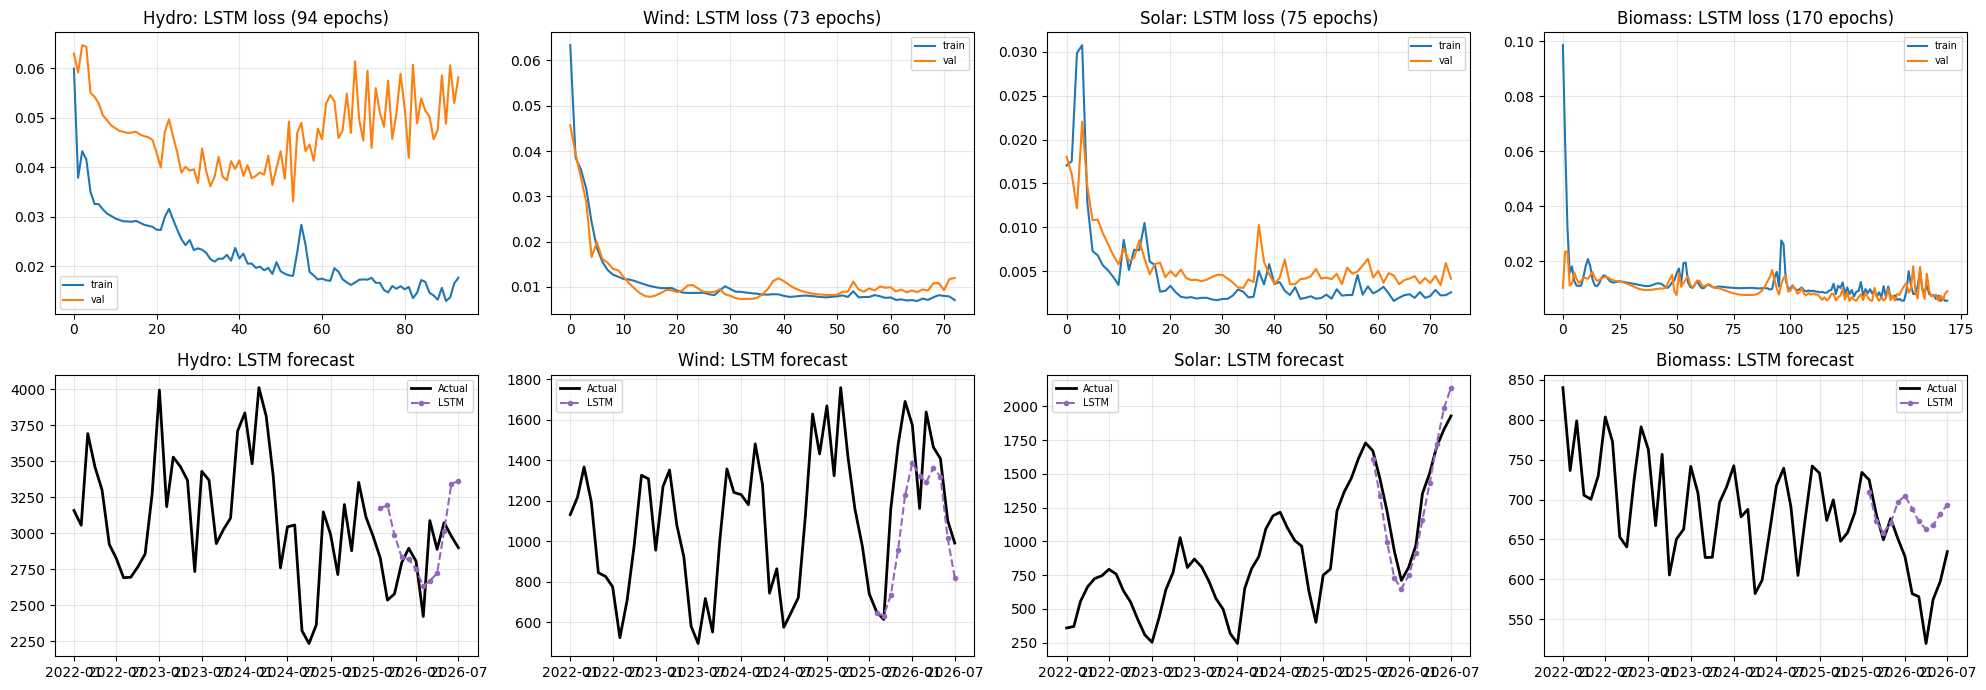

Training windows per source: 139


,,MAE,RMSE,MAPE %,sMAPE %,MASE
source,model,,,,,
hydro,LSTM,271.45,332.15,9.82,9.33,0.89
wind,LSTM,214.81,273.98,15.74,17.80,1.75
solar,LSTM,120.08,139.55,9.47,9.97,1.29
biomass,LSTM,61.71,75.49,10.54,9.74,1.27


In [21]:
WIN = 12
def lstm_forecast(y_hist, h, seed=42):
    tf.keras.utils.set_random_seed(seed)
    sc = MinMaxScaler(); st = sc.fit_transform(np.log(y_hist.values).reshape(-1, 1)).ravel()
    Xs = np.array([st[i:i+WIN] for i in range(len(st) - WIN)])[..., None]; ys = st[WIN:]
    net = keras.Sequential([keras.layers.Input((WIN, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])
    net.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
    hist = net.fit(Xs, ys, epochs=300, batch_size=8, verbose=0, validation_split=0.15, shuffle=False,
                   callbacks=[keras.callbacks.EarlyStopping(patience=40, restore_best_weights=True)])
    window, preds = list(st[-WIN:]), []
    for _ in range(h):
        p = float(net.predict(np.array(window[-WIN:])[None, :, None], verbose=0)[0, 0]); preds.append(p); window.append(p)
    fc = np.exp(sc.inverse_transform(np.array(preds).reshape(-1, 1)).ravel())
    in_fit = np.exp(sc.inverse_transform(net.predict(Xs, verbose=0)).ravel())
    return fc, pd.Series(y_hist.values[WIN:] - in_fit, index=y_hist.index[WIN:]), hist

fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, s in enumerate(SOURCES):
    fc, fitted_resid[s]["LSTM"], hist = lstm_forecast(TRAIN[s], H)
    forecasts[s]["LSTM"] = pd.Series(fc, index=test_idx)
    axes[0, j].plot(hist.history["loss"], label="train"); axes[0, j].plot(hist.history["val_loss"], label="val")
    axes[0, j].set_title(f"{s.capitalize()}: LSTM loss ({len(hist.history['loss'])} epochs)"); axes[0, j].legend(fontsize=7)
    axes[1, j].plot(Y[s].loc["2022":], "k", lw=2, label="Actual"); axes[1, j].plot(forecasts[s]["LSTM"], "--o", ms=3, color="tab:purple", label="LSTM")
    axes[1, j].set_title(f"{s.capitalize()}: LSTM forecast"); axes[1, j].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Training windows per source:", len(TRAIN["solar"]) - WIN)
pd.concat({s: score(s, ["LSTM"]) for s in SOURCES}, names=["source", "model"]).round(2)

**Interpretation**
- **Trees win for three sources:** RF for hydro (4.3 %) and solar (4.5 %); GBR/XGBoost for biomass (5.4 %).
- **Wind:** all tree models lose to seasonal naive.
- **Drivers:** lag-12 dominates hydro/wind/biomass; **month terms dominate solar**; covariate matters only for **biomass** (≈ 0.3).
- **LSTM** is mid-table — 139 windows are too few.

## 12. Forecast Accuracy

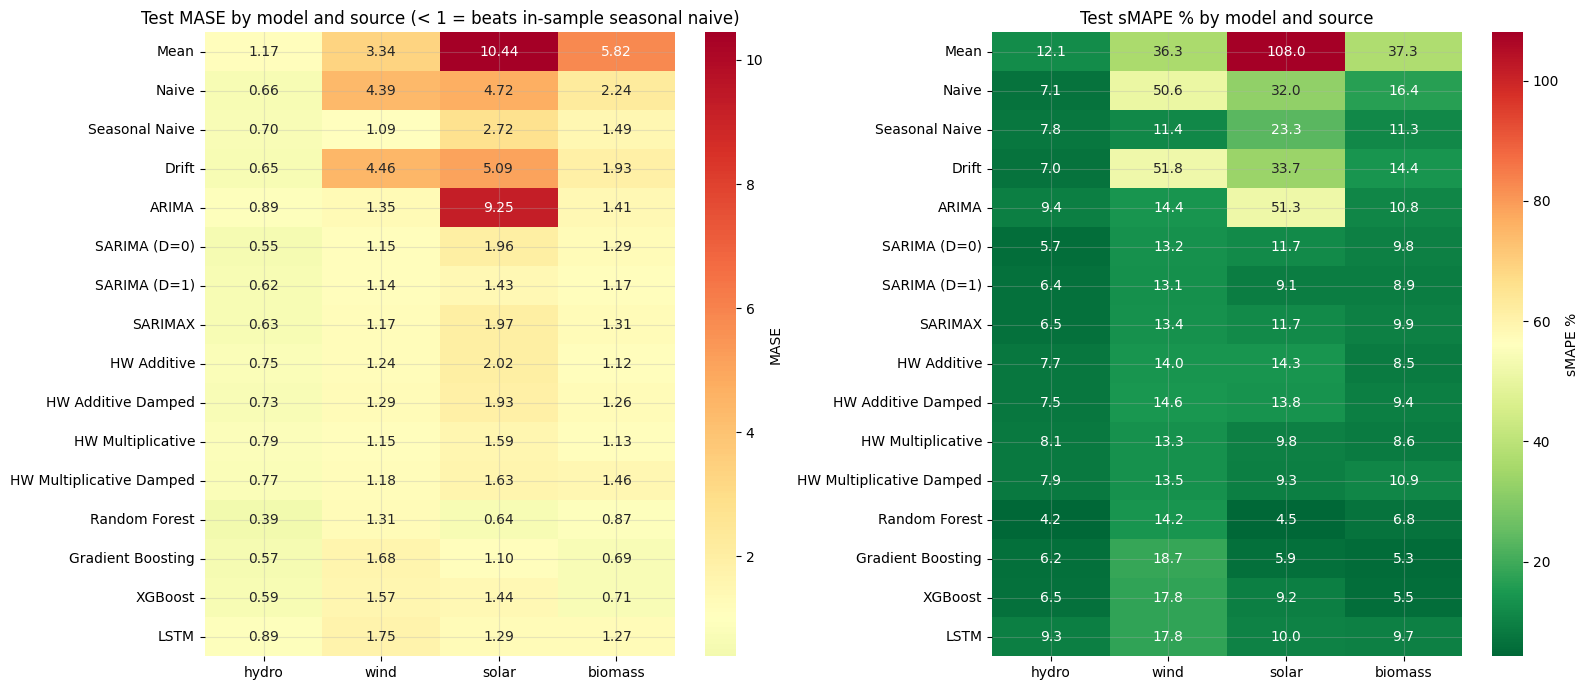

In [22]:
FAMILY = {**{k: "Baseline" for k in BASELINES}, **{k: "ARIMA-family" for k in ARIMA_MODELS},
          **{k: "Holt-Winters" for k in HW_SPECS}, **{k: "ML" for k in ML_MODELS}, "LSTM": "DL"}
acc = {s: score(s, list(forecasts[s])).assign(Family=lambda d: d.index.map(FAMILY)).sort_values("MASE") for s in SOURCES}
mase = pd.DataFrame({s: acc[s]["MASE"] for s in SOURCES}).loc[list(forecasts["solar"])]
smape = pd.DataFrame({s: acc[s]["sMAPE %"] for s in SOURCES}).loc[list(forecasts["solar"])]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(mase, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1, ax=axes[0], cbar_kws={"label": "MASE"})
axes[0].set_title("Test MASE by model and source (< 1 = beats in-sample seasonal naive)")
sns.heatmap(smape, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axes[1], cbar_kws={"label": "sMAPE %"})
axes[1].set_title("Test sMAPE % by model and source")
plt.tight_layout(); plt.show()

### 12.1 Robustness — rolling-origin evaluation
Refit at **Jul 2023, Jul 2024, Jul 2025**; forecast 12 months each (36 test months). Orders fixed; LSTM excluded. **The winner here is each source's final model (Section 15).**

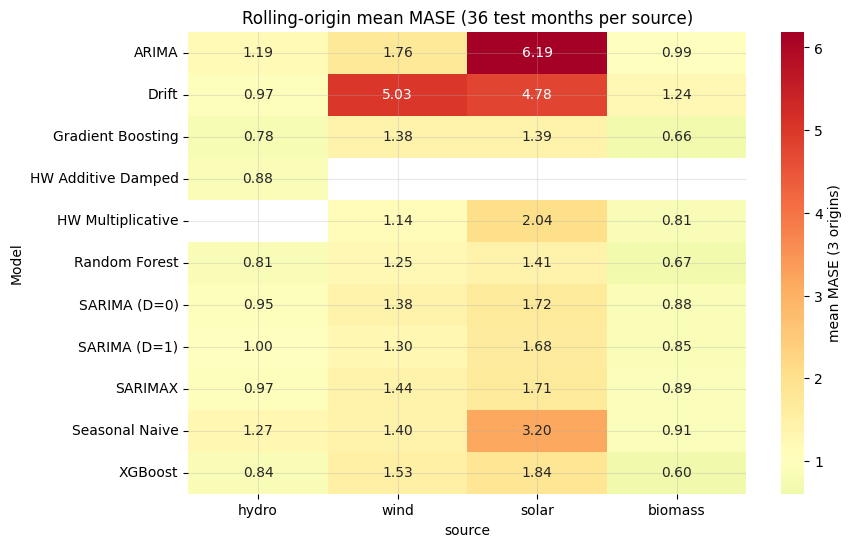

,best model (rolling-origin),mean MASE,mean sMAPE %,Seasonal Naive mean MASE,best on single test year
hydro,Gradient Boosting,0.780,7.556,1.275,Random Forest
wind,HW Multiplicative,1.136,12.315,1.396,Seasonal Naive
solar,Gradient Boosting,1.395,11.199,3.197,Random Forest
biomass,XGBoost,0.603,4.640,0.913,Gradient Boosting


In [23]:
ORIGINS = ["2023-07-01", "2024-07-01", "2025-07-01"]

def forecast_model(s, name, y_hist, f_idx, exog_future=None):
    # Re-fit model `name` for source s on y_hist and forecast f_idx.
    # Exog for f_idx: observed values if available, otherwise exog_future (a forecast).
    xs = XEXO[s] if exog_future is None else pd.concat([XEXO[s], exog_future])
    if name in BASELINES:
        return baseline(name, y_hist, f_idx)
    if name in ARIMA_MODELS:
        o, so = selected[s][name]
        ex_tr, ex_te = (xs.loc[y_hist.index].to_frame(), xs.loc[f_idx].to_frame()) if name == "SARIMAX" else (None, None)
        f = fit_sarimax(np.log(y_hist), o, so, exog=ex_tr)
        return pd.Series(np.exp(f.forecast(len(f_idx), exog=ex_te).values), index=f_idx)
    if name in HW_SPECS:
        return pd.Series(hw_fit(y_hist, name).forecast(len(f_idx)).values, index=f_idx)
    if name in ML_MODELS:
        return tree_forecast(name, y_hist, xs.diff(), f_idx)[0]
    raise ValueError(name)

ro_rows = []
for s in SOURCES:
    models = ["Seasonal Naive", "Drift", *ARIMA_MODELS, best_hw[s], *ML_MODELS]
    for origin in ORIGINS:
        tr = Y[s].loc[:origin]; te = Y[s].loc[origin:].iloc[1:H + 1]
        for name in models:
            ro_rows.append({"source": s, "origin": origin[:7], "Model": name,
                            **metrics(te, forecast_model(s, name, tr, te.index), tr)})
ro = pd.DataFrame(ro_rows)
ro_mean = ro.groupby(["source", "Model"])[["MASE", "sMAPE %"]].mean()
ro_mase = ro.pivot_table(index="Model", columns="source", values="MASE", aggfunc="mean")[SOURCES]

plt.figure(figsize=(9, 6))
sns.heatmap(ro_mase, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1, cbar_kws={"label": "mean MASE (3 origins)"})
plt.title("Rolling-origin mean MASE (36 test months per source)"); plt.show()

final_choice = {s: ro_mean.loc[s, "MASE"].idxmin() for s in SOURCES}
pd.DataFrame({"best model (rolling-origin)": final_choice,
              "mean MASE": {s: ro_mean.loc[(s, final_choice[s]), "MASE"] for s in SOURCES},
              "mean sMAPE %": {s: ro_mean.loc[(s, final_choice[s]), "sMAPE %"] for s in SOURCES},
              "Seasonal Naive mean MASE": {s: ro_mean.loc[(s, "Seasonal Naive"), "MASE"] for s in SOURCES},
              "best on single test year": {s: acc[s].index[0] for s in SOURCES}}).round(3)

**Interpretation**

| Source | Best — test year | Best — 3 rolling years (MASE) |
|---|---|---|
| Hydro | Random Forest | **Gradient Boosting (0.78)** |
| Wind | Seasonal Naive | **HW Multiplicative (1.14)** |
| Solar | Random Forest | **Gradient Boosting (1.39)** |
| Biomass | Gradient Boosting | **XGBoost (0.60)** |

- **Boosted trees** are the most consistent family for hydro, solar and biomass.
- **Wind shows almost no skill** beyond repeating last year.

## 13. Model Comparison

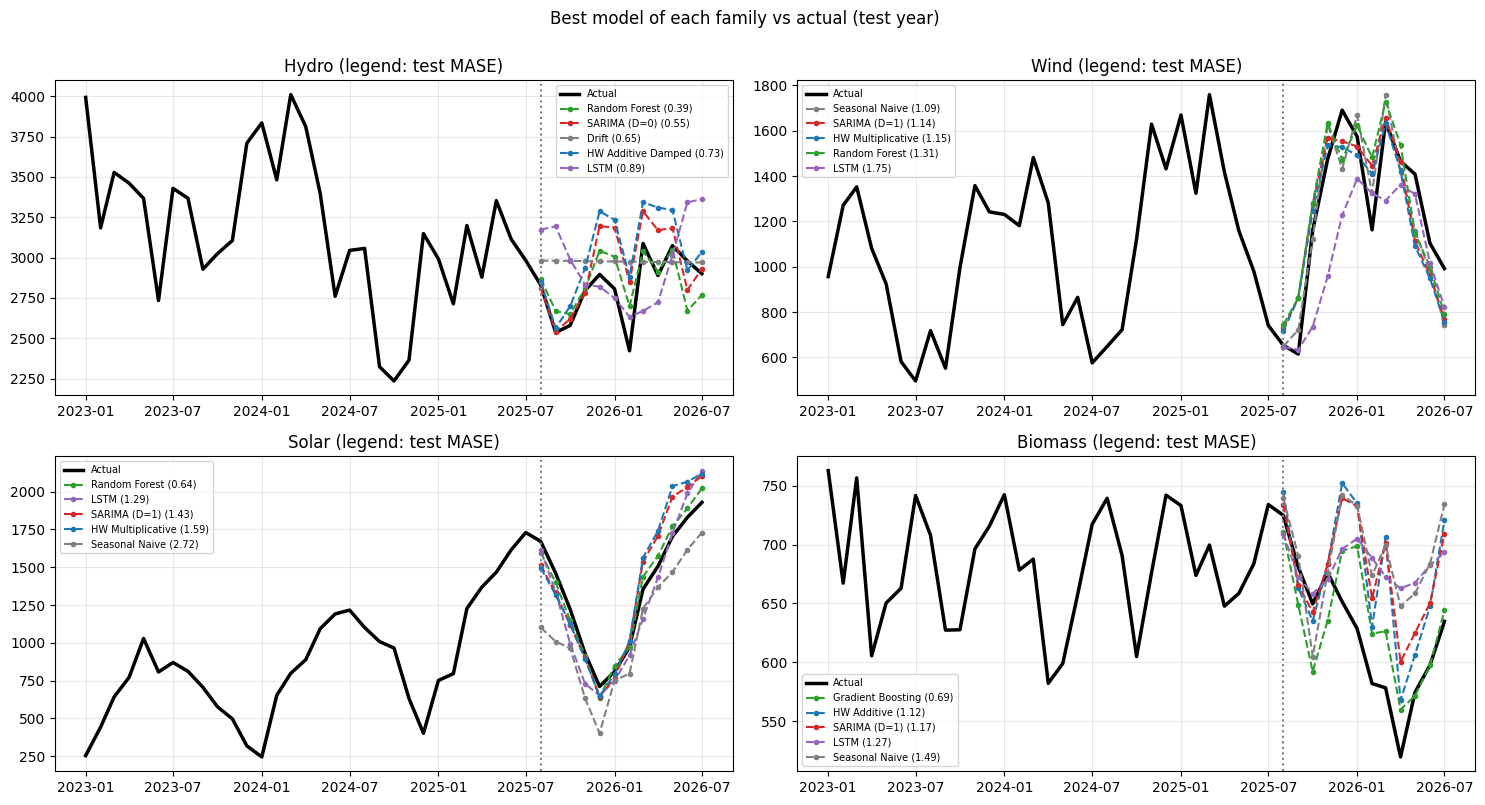

Model     MAE    RMSE  sMAPE %  MASE
source  Family                                                         
hydro   ML                 Random Forest  117.64  151.92     4.24  0.39
        ARIMA-family        SARIMA (D=0)  165.56  220.71     5.67  0.55
        Baseline                   Drift  196.72  256.57     6.99  0.65
        Holt-Winters  HW Additive Damped  222.66  273.04     7.52  0.73
        DL                          LSTM  271.45  332.15     9.33  0.89
wind    Baseline          Seasonal Naive  134.39  157.17    11.36  1.09
        ARIMA-family        SARIMA (D=1)  140.05  170.61    13.10  1.14
        Holt-Winters   HW Multiplicative  141.95  171.29    13.26  1.15
        ML                 Random Forest  161.05  181.40    14.22  1.31
        DL                          LSTM  214.81  273.98    17.80  1.75
solar   ML                 Random Forest   59.00   64.63     4.54  0.64
        DL                          LSTM  120.08  139.55     9.97  1.29
        ARIMA-family        SARIMA (D=1)  132.85  151.59     9.10  1.43
        Holt-Winters   HW Multiplicative  147.81  175.40     9.76  1.59
        Baseline          Seasonal Naive  253.02  287.38    23.35  2.72
biomass ML             Gradient Boosting   33.41   39.57     5.31  0.69
        Holt-Winters         HW Additive   54.84   67.27     8.45  1.12
        ARIMA-family        SARIMA (D=1)   57.02   68.75     8.91  1.17
        DL                          LSTM   61.71   75.49     9.74  1.27
        Baseline          Seasonal Naive   72.90   84.32    11.34  1.49

In [24]:
fam_colors = {"Baseline": "grey", "ARIMA-family": "tab:red", "Holt-Winters": "tab:blue", "ML": "tab:green", "DL": "tab:purple"}
best_fam = pd.concat({s: acc[s].reset_index(names="Model").groupby("Family").head(1).set_index("Family") for s in SOURCES}, names=["source"])
fig, ax = grid2x2("Best model of each family vs actual (test year)")
for s in SOURCES:
    ax[s].plot(Y[s].loc["2023":], "k", lw=2.5, label="Actual")
    for fam, r in best_fam.loc[s].iterrows():
        ax[s].plot(forecasts[s][r.Model], "--", marker="o", ms=3, color=fam_colors[fam], label=f"{r.Model} ({r.MASE:.2f})")
    ax[s].axvline(test_idx[0], color="grey", ls=":"); ax[s].set_title(f"{s.capitalize()} (legend: test MASE)"); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()
best_fam[["Model", "MAE", "RMSE", "sMAPE %", "MASE"]].round(2)

In [25]:
# Diebold–Mariano test (squared-error loss, h=1 variance with HLN small-sample correction) vs Seasonal Naive
def dm_test(actual, f1, f2, h=1):
    d = (actual - f1) ** 2 - (actual - f2) ** 2
    n = len(d); dbar = d.mean()
    dm = dbar / np.sqrt(np.var(d, ddof=0) / n)
    dm *= np.sqrt((n + 1 - 2*h + h*(h-1)/n) / n)
    return dm, 2 * stats.t.sf(np.abs(dm), df=n - 1)

dm_rows = []
for s in SOURCES:
    for m_ in acc[s].index.drop("Seasonal Naive"):
        dm, p = dm_test(TEST[s], forecasts[s][m_], forecasts[s]["Seasonal Naive"])
        dm_rows.append({"source": s, "Model": m_, "DM stat": dm, "p-value": p,
                        "vs Seasonal Naive (5%)": "significantly better" if (dm < 0 and p < .05) else
                                                  ("significantly worse" if (dm > 0 and p < .05) else "no significant difference")})
dm_tab = pd.DataFrame(dm_rows).set_index(["source", "Model"])
print("Significant differences vs Seasonal Naive (5%); all other models: no significant difference")
dm_tab[dm_tab["vs Seasonal Naive (5%)"] != "no significant difference"].round(3)

Significant differences vs Seasonal Naive (5%); all other models: no significant difference


DM stat  p-value vs Seasonal Naive (5%)
source  Model                                                     
hydro   Mean                 2.240    0.047    significantly worse
wind    XGBoost              2.766    0.018    significantly worse
        Gradient Boosting    3.484    0.005    significantly worse
        Mean                 3.450    0.005    significantly worse
        Naive                3.848    0.003    significantly worse
        Drift                3.902    0.002    significantly worse
solar   Random Forest       -2.925    0.014   significantly better
        LSTM                -2.211    0.049   significantly better
        ARIMA                4.278    0.001    significantly worse
        Mean                 4.531    0.001    significantly worse
biomass Gradient Boosting   -3.509    0.005   significantly better
        XGBoost             -3.433    0.006   significantly better
        Random Forest       -3.848    0.003   significantly better
        HW Multiplicative   -3.023    0.012   significantly better
        SARIMA (D=1)        -2.679    0.021   significantly better
        Naive                2.873    0.015    significantly worse
        Mean                 9.361    0.000    significantly worse

**Interpretation**
- **Best family per source (test year):** hydro — ML; wind — baseline ≈ ARIMA ≈ HW; solar — ML; biomass — ML.
- **Diebold–Mariano vs seasonal naive:** biomass — 5 models significantly better; solar — RF and LSTM; hydro and wind — none (12 test months is short).
- **Wind:** GBR and XGBoost are significantly **worse**.

## 14. Residual Analysis

In [26]:
def resid_diag(r):
    r = r.dropna()
    lb = acorr_ljungbox(r, lags=[6, 12], return_df=True)
    return {"n": len(r), "mean": r.mean(), "std": r.std(),
            "Ljung-Box p (6)": lb.lb_pvalue.iloc[0], "Ljung-Box p (12)": lb.lb_pvalue.iloc[1],
            "Shapiro p": stats.shapiro(r).pvalue, "Jarque-Bera p": stats.jarque_bera(r).pvalue,
            "ARCH-LM p": het_arch(r, nlags=4)[1]}

# best model of each family (Section 13) + the final forecasting model (Section 12.1); baselines have no residuals
diag_models = {s: [m_ for m_ in dict.fromkeys([*best_fam.loc[s, "Model"], final_choice[s]]) if m_ in fitted_resid[s]] for s in SOURCES}
diag_tab = pd.concat({s: pd.DataFrame({m_: resid_diag(fitted_resid[s][m_]) for m_ in diag_models[s]}).T for s in SOURCES}, names=["source", "Model"])
diag_tab["final model"] = [m_ == final_choice[s] for s, m_ in diag_tab.index]
diag_tab["white noise (LB12 p>0.05)"] = np.where(diag_tab["Ljung-Box p (12)"] > .05, "yes", "no")
diag_tab.round(3)

n    mean      std  Ljung-Box p (6)  \
source  Model                                                         
hydro   Random Forest       138.0   4.000  134.398            0.360   
        SARIMA (D=0)        138.0  -3.694  244.183            0.844   
        HW Additive Damped  151.0   1.790  215.129            0.063   
        LSTM                139.0  30.098  259.091            0.448   
        Gradient Boosting   138.0   2.878  134.022            0.688   
wind    SARIMA (D=1)        126.0   0.206  136.557            0.497   
        HW Multiplicative   151.0  -0.377  113.156            0.297   
        Random Forest       138.0   4.434   79.928            0.004   
        LSTM                139.0 -43.206  133.247            0.025   
solar   Random Forest       138.0   0.714   40.496            0.000   
        LSTM                139.0  21.424   71.063            0.272   
        SARIMA (D=1)        126.0   6.254   61.607            0.068   
        HW Multiplicative   151.0   8.203   54.282            0.004   
        Gradient Boosting   138.0   0.112   32.798            0.000   
biomass Gradient Boosting   138.0   0.058   20.309            0.045   
        HW Additive         151.0  -0.000   31.363            0.493   
        SARIMA (D=1)        126.0  -2.116   32.690            0.569   
        LSTM                139.0  14.825   58.931            0.336   
        XGBoost             138.0   0.240   17.328            0.222   

                            Ljung-Box p (12)  Shapiro p  Jarque-Bera p  \
source  Model                                                            
hydro   Random Forest                  0.031      0.003          0.000   
        SARIMA (D=0)                   0.400      0.157          0.093   
        HW Additive Damped             0.021      0.048          0.021   
        LSTM                           0.128      0.936          0.892   
        Gradient Boosting              0.197      0.121          0.027   
wind    SARIMA (D=1)                   0.553      0.427          0.901   
        HW Multiplicative              0.699      0.499          0.644   
        Random Forest                  0.045      0.208          0.231   
        LSTM                           0.155      0.441          0.646   
solar   Random Forest                  0.000      0.000          0.000   
        LSTM                           0.062      0.000          0.000   
        SARIMA (D=1)                   0.249      0.000          0.000   
        HW Multiplicative              0.059      0.000          0.000   
        Gradient Boosting              0.000      0.000          0.000   
biomass Gradient Boosting              0.022      0.584          0.652   
        HW Additive                    0.321      0.721          0.163   
        SARIMA (D=1)                   0.486      0.501          0.464   
        LSTM                           0.000      0.903          0.657   
        XGBoost                        0.045      0.809          0.850   

                            ARCH-LM p  final model white noise (LB12 p>0.05)  
source  Model                                                                 
hydro   Random Forest           0.306        False                        no  
        SARIMA (D=0)            0.211        False                       yes  
        HW Additive Damped      0.458        False                        no  
        LSTM                    0.188        False                       yes  
        Gradient Boosting       0.398         True                       yes  
wind    SARIMA (D=1)            0.061        False                       yes  
        HW Multiplicative       0.091         True                       yes  
        Random Forest           0.071        False                        no  
        LSTM                    0.146        False                       yes  
solar   Random Forest           0.077        False                        no  
        LSTM                    0.193

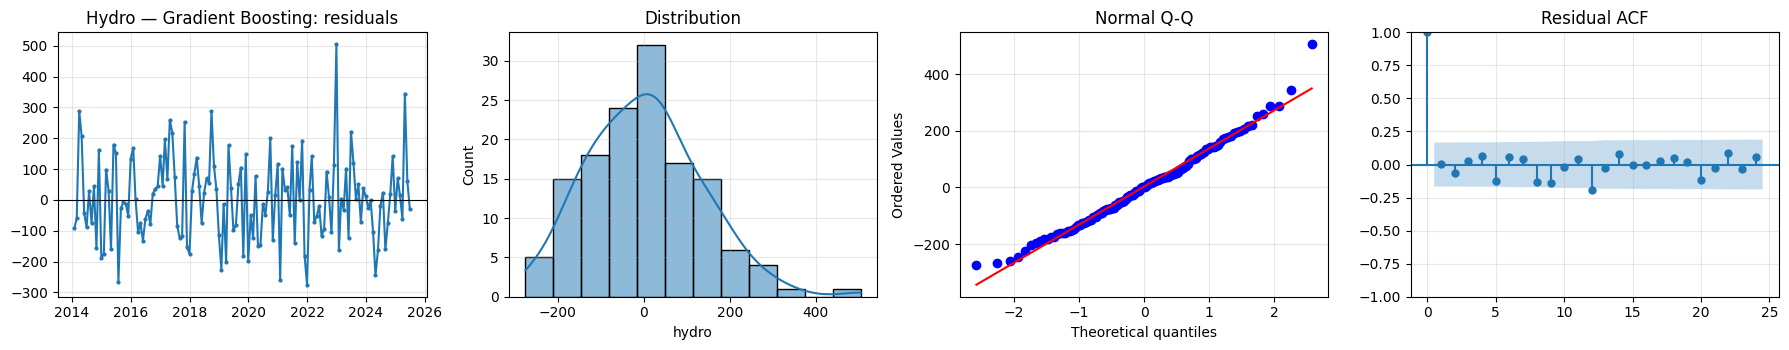

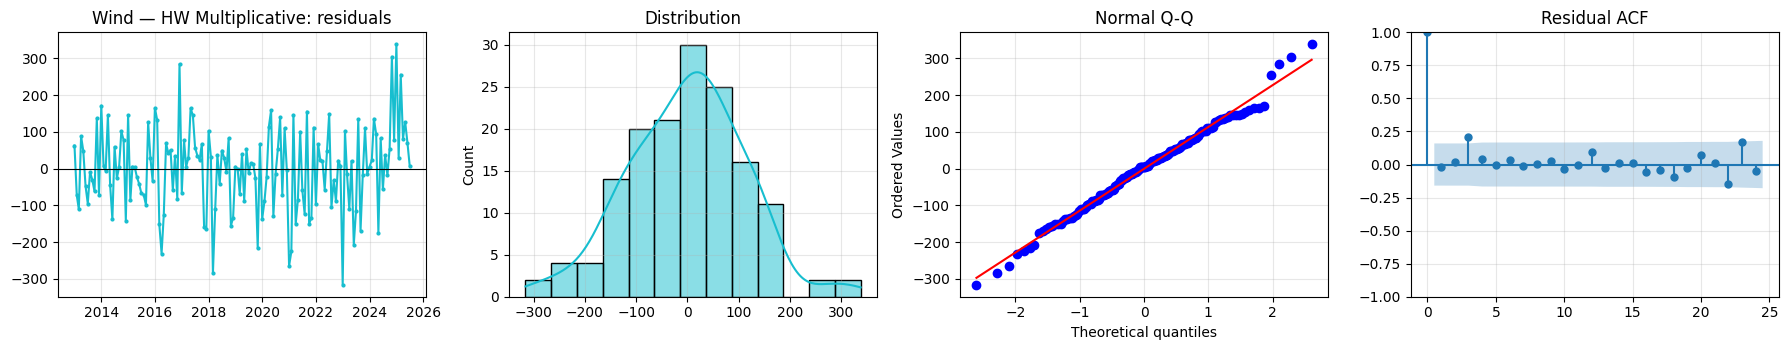

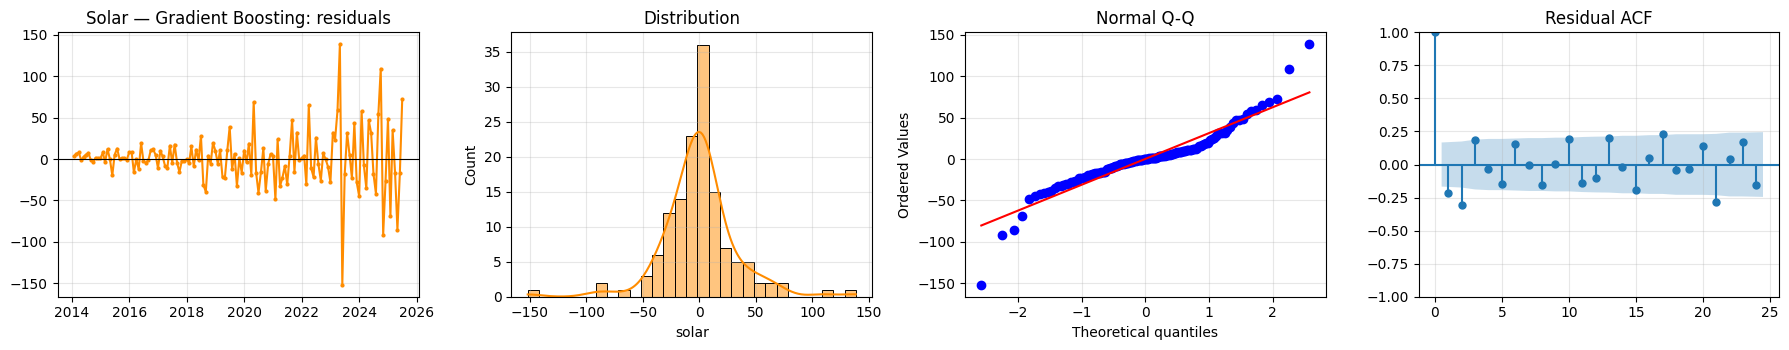

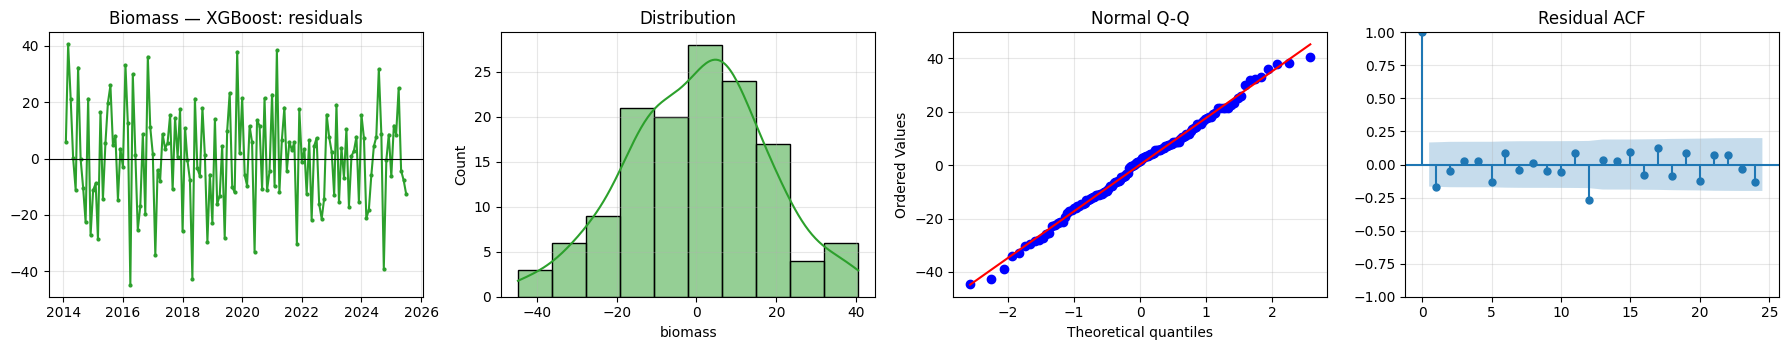

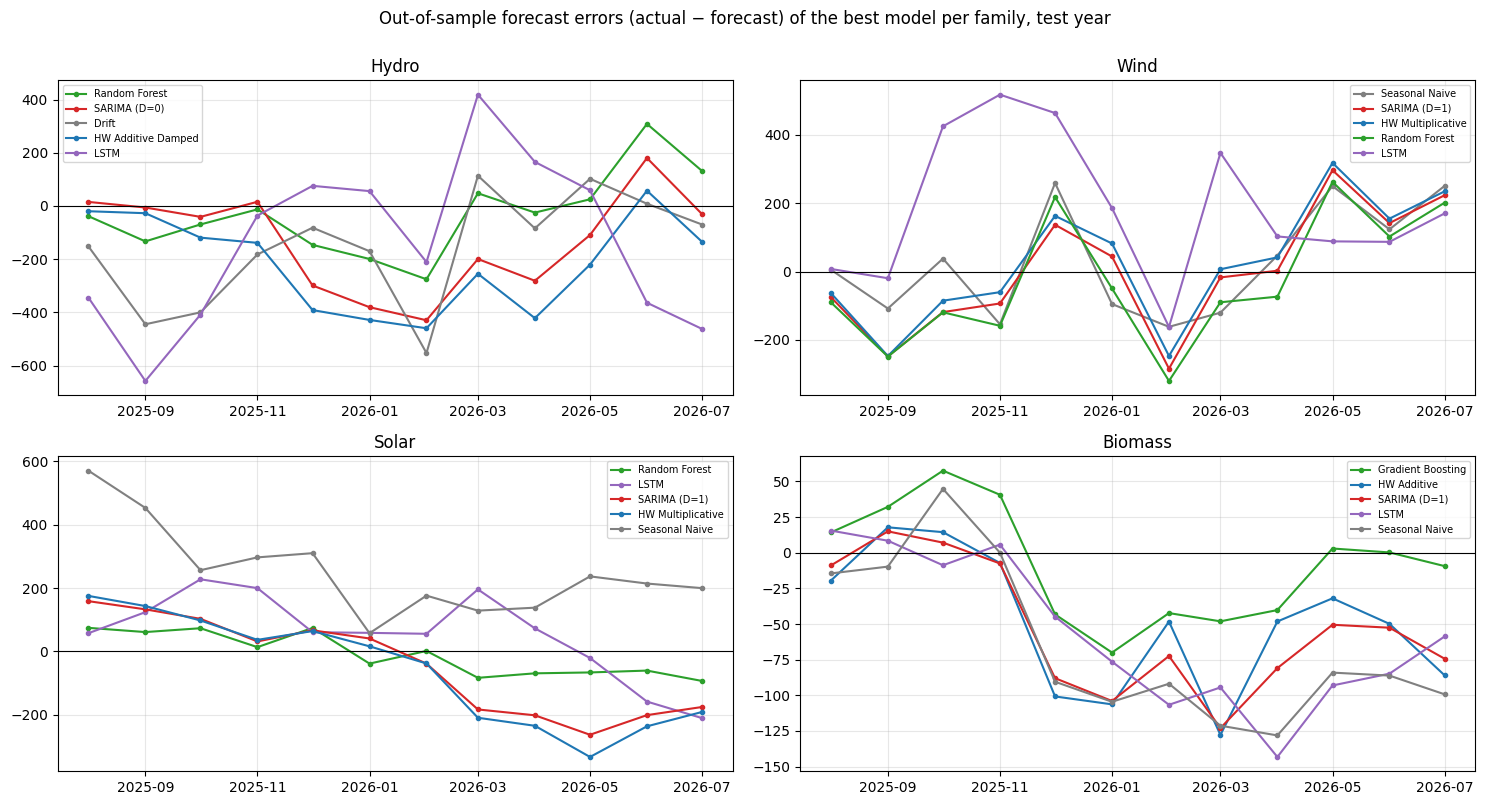

In [ ]:
for s in SOURCES:
    # final model if it has in-sample residuals (baselines do not), else the best fitted model on the test year
    name = next(m_ for m_ in [final_choice[s], *acc[s].index] if m_ in fitted_resid[s])
    r = fitted_resid[s][name].dropna()
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    axes[0].plot(r, marker="o", ms=2, color=COLORS[s]); axes[0].axhline(0, color="k", lw=.8); axes[0].set_title(f"{s.capitalize()} — {name}: residuals")
    sns.histplot(r, kde=True, ax=axes[1], color=COLORS[s]); axes[1].set_title("Distribution")
    stats.probplot(r, dist="norm", plot=axes[2]); axes[2].set_title("Normal Q-Q")
    plot_acf(r, lags=24, ax=axes[3], title="Residual ACF")
    plt.tight_layout(); plt.show()

fig, ax = grid2x2("Out-of-sample forecast errors (actual − forecast) of the best model per family, test year")
for s in SOURCES:
    
    for fam, r in best_fam.loc[s].iterrows():
        ax[s].plot(TEST[s] - forecasts[s][r.Model], marker="o", ms=3, color=fam_colors[fam], label=r.Model)
    ax[s].axhline(0, color="k", lw=.8); ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation** — good residuals: mean ≈ 0, Ljung-Box p > 0.05, normal, no ARCH.

| Source | White noise | Autocorrelated | Note |
|---|---|---|---|
| Hydro | SARIMA D=0, **GBR (final)**, LSTM | RF, HW | SARIMA passes all checks → reliable intervals |
| Wind | SARIMA D=1, **HW mult. (final)**, LSTM | RF | Borderline ARCH → intervals may be too narrow in volatile winters |
| Solar | SARIMA D=1, HW mult., LSTM | RF, **GBR (final)** | Non-normal for all; spread grows with capacity |
| Biomass | SARIMA D=1, HW add. | **GBR, XGBoost (final)**, LSTM | SARIMA D=1 passes all checks |

- The final tree models for solar and biomass leave some autocorrelation → use the SARIMA intervals (Section 15) for uncertainty.

## 15. Separate 12-Month Forecasts for Each Source (Aug 2026 – Jul 2027)
Each source's **rolling-origin winner** is refit on all data. Future covariate from damped Holt-Winters; band = SARIMA 95 % PI. Sources are summed into a **total-renewable outlook**.

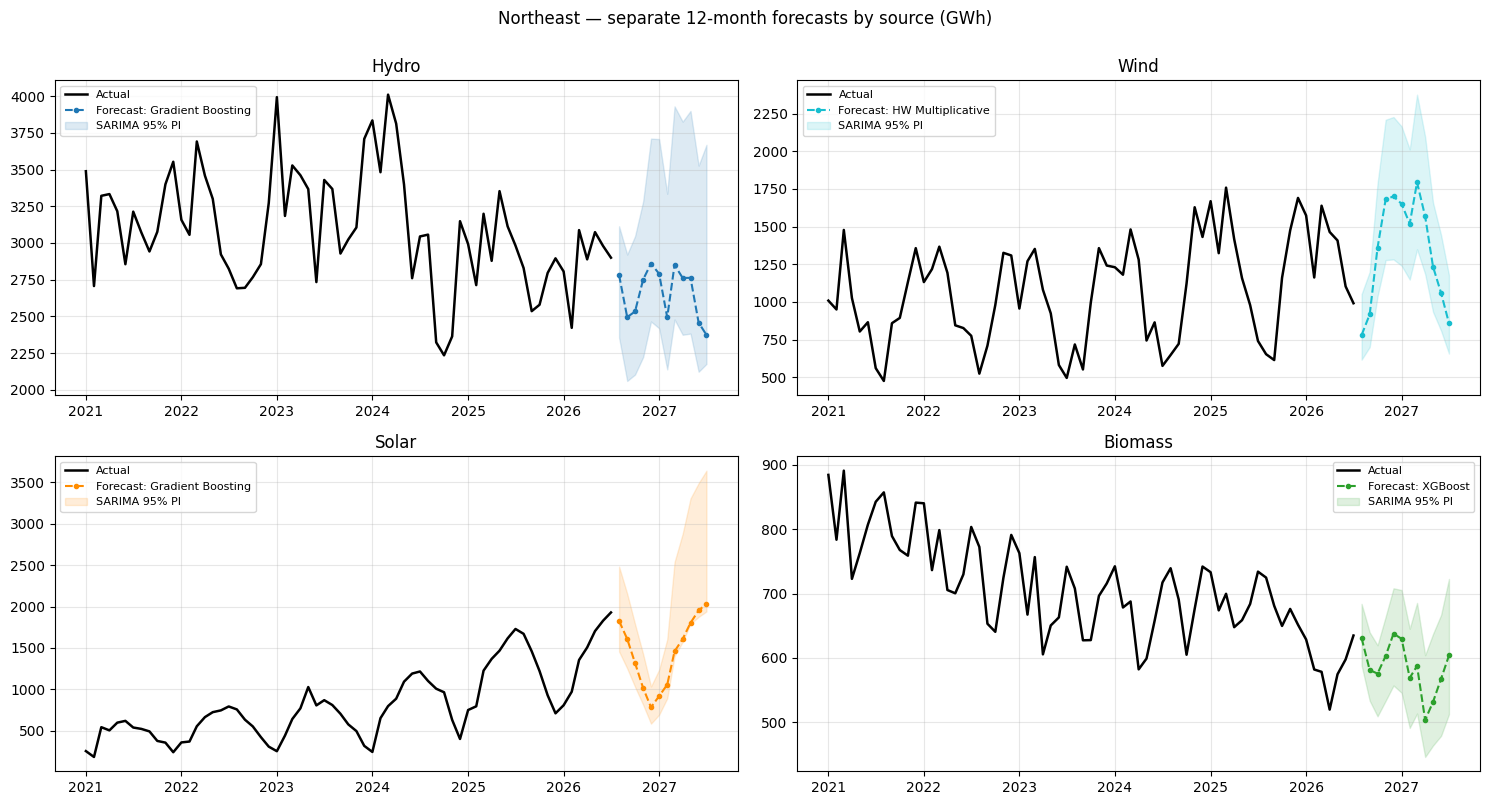

,hydro,wind,solar,biomass,total renewable
2026-08-01,2781.3,779.6,1827.0,630.8,6018.7
2026-09-01,2495.1,917.4,1609.5,581.1,5603.0
2026-10-01,2533.6,1360.3,1318.8,575.6,5788.3
2026-11-01,2751.3,1681.5,1015.3,603.0,6051.0
2026-12-01,2860.3,1701.0,784.0,637.6,5982.9
2027-01-01,2790.3,1651.1,918.5,629.6,5989.5
2027-02-01,2494.0,1519.2,1057.1,568.9,5639.3
2027-03-01,2850.8,1794.1,1459.4,587.4,6691.7
2027-04-01,2762.0,1567.6,1608.5,503.4,6441.5
2027-05-01,2762.7,1234.7,1803.2,531.5,6332.0


,model used,rolling-origin MASE,last 12 months (GWh),next 12 months (GWh),change %,share of next-12m renewables %
hydro,Gradient Boosting,0.78,33794.03,31913.22,-5.57,44.05
wind,HW Multiplicative,1.14,14936.56,16123.99,7.95,22.26
solar,Gradient Boosting,1.39,16096.50,17388.98,8.03,24.00
biomass,XGBoost,0.60,7498.14,7020.21,-6.37,9.69
total renewable,sum of sources,NaN,72325.24,72446.41,0.17,100.00


In [28]:
f_idx = pd.date_range(df.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")
future, future_ci = {}, {}
for s in SOURCES:
    x_fc = ExponentialSmoothing(XEXO[s], trend="add", seasonal="add", damped_trend=True, seasonal_periods=12,
                                initialization_method="estimated").fit().forecast(12)
    future[s] = forecast_model(s, final_choice[s], Y[s], f_idx, exog_future=pd.Series(x_fc.values, index=f_idx, name="log_rest"))
    o, so = selected[s]["SARIMA (D=0)"]
    future_ci[s] = np.exp(fit_sarimax(np.log(Y[s]), o, so).get_forecast(12).conf_int().values)

fig, ax = grid2x2("Northeast — separate 12-month forecasts by source (GWh)")
for s in SOURCES:
    ax[s].plot(Y[s].loc["2021":], "k", lw=1.8, label="Actual")
    ax[s].plot(future[s], "--o", ms=3, color=COLORS[s], label=f"Forecast: {final_choice[s]}")
    ax[s].fill_between(f_idx, future_ci[s][:, 0], future_ci[s][:, 1], color=COLORS[s], alpha=.15, label="SARIMA 95% PI")
    ax[s].set_title(s.capitalize()); ax[s].legend(fontsize=8)
plt.tight_layout(); plt.show()

fut = pd.DataFrame(future)
fut["total renewable"] = fut.sum(axis=1)
display(fut.round(1))

last12 = df[SOURCES].iloc[-12:].sum()
outlook = pd.DataFrame({"model used": pd.Series(final_choice),
                        "rolling-origin MASE": {s: ro_mean.loc[(s, final_choice[s]), "MASE"] for s in SOURCES},
                        "last 12 months (GWh)": last12, "next 12 months (GWh)": fut[SOURCES].sum()})
outlook.loc["total renewable"] = ["sum of sources", np.nan, last12.sum(), fut["total renewable"].sum()]
outlook["change %"] = 100 * (outlook["next 12 months (GWh)"].astype(float) / outlook["last 12 months (GWh)"].astype(float) - 1)
outlook["share of next-12m renewables %"] = 100 * outlook["next 12 months (GWh)"].astype(float) / fut["total renewable"].sum()
outlook.round(2)

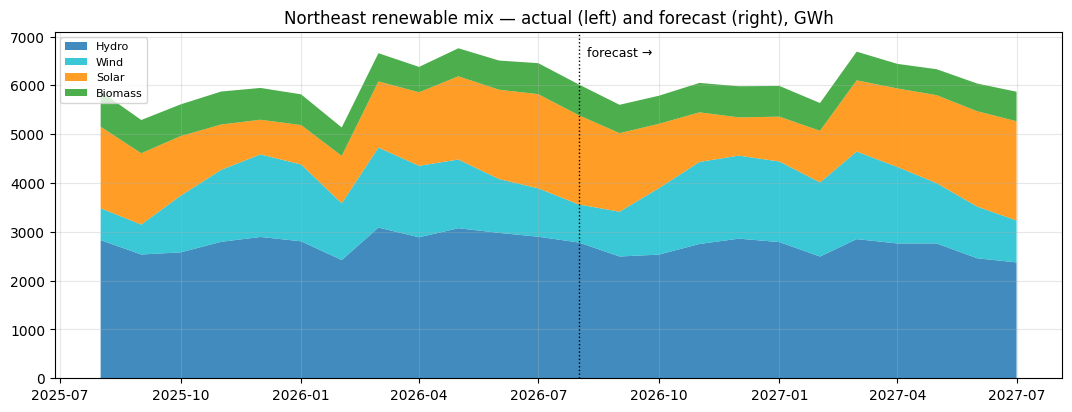

In [29]:
# Renewable mix: last 12 months (actual) and next 12 months (forecast)
mix = pd.concat([df[SOURCES].iloc[-12:], fut[SOURCES]])
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.stackplot(mix.index, *[mix[s] for s in SOURCES], labels=[s.capitalize() for s in SOURCES],
             colors=[COLORS[s] for s in SOURCES], alpha=.85)
ax.axvline(f_idx[0], color="k", ls=":", lw=1); ax.text(f_idx[0], ax.get_ylim()[1] * .93, "  forecast →", fontsize=9)
ax.set_title("Northeast renewable mix — actual (left) and forecast (right), GWh"); ax.legend(loc="upper left", fontsize=8)
plt.show()

**Interpretation**

| Source | Model | Next 12 months | Change |
|---|---|---|---|
| Hydro | Gradient Boosting | ≈ 31,900 GWh | −5.6 % |
| Wind | HW Multiplicative | ≈ 16,100 GWh | +8.0 % |
| Solar | Gradient Boosting | ≈ 17,400 GWh | +8.0 % |
| Biomass | XGBoost | ≈ 7,020 GWh | −6.4 % |
| **Total** | sum | **≈ 72,450 GWh** | **+0.2 %** |

- **Solar (24 %) overtakes wind (22 %)**; hydro stays largest (44 %).
- Solar growth is damped by the tree model — SARIMA/HW would forecast higher.
- Wind is the least reliable forecast.

## 16. Research Conclusion

### Answers

**RQ1 — Patterns.** Hydro flat (Mar peak, 74 % NY); wind +3.5 %/yr (strongest seasonality); solar +27 %/yr (Jul peak); biomass −5 %/yr (Dec peak). Offset peaks smooth the total.

**RQ2 — Stationarity.** **log + d = 1** for all four; ACF/PACF → seasonal AR(1); AIC adds a seasonal MA.

**RQ3 — Best model.** Hydro **Gradient Boosting**, wind **HW Multiplicative**, solar **Gradient Boosting**, biomass **XGBoost** (3-year rolling MASE).

**RQ4 — Covariate.** **No.** Significant only for hydro, and SARIMAX never beats SARIMA out of sample; useful only inside tree models for biomass.

**RQ5 — Forecastability & outlook.** By 3-year sMAPE: **biomass (4.6 %) > hydro (7.6 %) > solar (11.2 %) > wind (12.3 %, barely beats seasonal naive).** Next 12 months: **≈ 72.4 TWh total (+0.2 %)** — solar and wind up, hydro and biomass down.

### Limitations
- No weather data (rain, snowpack, wind speed, irradiance) — the main improvement to make.
- Only 12–36 test months.

**Conclusion:** forecast each source with its own model — **boosted trees on log-growth** for hydro, solar and biomass; a **seasonal model** for wind. Total renewables stay **flat (≈ +0.2 %)** as the mix shifts towards solar and wind.